# Laboratorio 3 — La tarea de clasificación
## Caso: Ruta Alpes — Recomendación de cupones (Cafetería y Restaurante(<20))

**Curso:** ISIS-2611 Aprendizaje de Máquina — Universidad de los Andes

**Integrantes:**
- Julian Pinto 202321207
- Daniel Vergara 202320392

---

**Objetivo del negocio.** Ruta Alpes quiere saber, para un tipo de cupón dado, *cuándo* un conductor tiene mayor probabilidad de aceptarlo, para dejar de enviar la misma oferta a todos los usuarios. Se construyen clasificadores binarios (`acepta_cupon` = Sí / No) para dos tipos de cupón: **Cafetería** y **Restaurante(<20)**. Se comparan regresión logística, árboles de decisión y Random Forest; se evalúa el balanceo de clases en Restaurante(<20) y se discuten riesgos de sesgo del uso de variables demográficas.

**Contenido**
1. Exploración y calidad de datos
2. Limpieza y preparación
3. Regresión logística
4. Árboles de decisión
5. Random Forest
6. Balanceo de clases (SMOTEN) en Restaurante(<20)
7. Tabla comparativa y selección del mejor modelo
8. Variables más relevantes
9. Predicciones sobre `Lab3_datos_Prueba`
10. Análisis de resultados
11. Uso de herramientas de IA generativa



### Base en las prácticas de clase

- [P1](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P1_Exploraci%C3%B3n%20y%20calidad%20de%20datos/P1_ManipulacionExploracionCalidad.ipynb): estadísticas, nulos, duplicados y dominios.
- [P2](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P2_Limpieza%20y%20preparaci%C3%B3n/P2_LimpiezaTransformacion.ipynb): imputación y codificación ordinal/One-Hot.
- [P7](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P7_Regresi%C3%B3n%20log%C3%ADstica/P7_RegresionLogistica.ipynb): pipeline, escalado y grids compatibles de regularización/solver.
- [P8](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P8_%C3%81rboles%20de%20decisi%C3%B3n/ArbolesDecision.ipynb): pipeline, control de complejidad e interpretación del árbol.
- [P9](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P9_KNN_SMOTE/P9_KNN_SMOTE.ipynb): F1-macro y balanceo dentro de los folds.
- [P10](https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611/blob/4f515e3883f487a555f846e8e0aee1b5f4f3a2fa/202620/Pr%C3%A1cticas/P10_Ensembles/P10_RandomForest.ipynb): grid de bosque, métricas e importancia de variables.

Se amplían los grids del avance y se usan dos problemas binarios independientes. En scikit-learn 1.9.1 se expresa L1/L2 con `l1_ratio`, en lugar del `penalty` de P7; los solvers y las penalizaciones conservan su significado. Se entregan las métricas de ambas clases y F1-macro. Las referencias corresponden al commit `4f515e3` del curso.


In [1]:
from pathlib import Path
from sklearn.base import clone
from joblib import Memory, parallel_config
import sklearn, imblearn

# Caché de transformaciones: evita repetir la imputación y el balanceo por cada candidato.
CACHE = Memory('tmp/cache_pipeline', verbose=0)
N_JOBS = 4
print('scikit-learn:', sklearn.__version__, '| imbalanced-learn:', imblearn.__version__)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTEN

pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
CUPONES = ['Cafetería', 'Restaurante(<20)']

scikit-learn: 1.9.1 | imbalanced-learn: 0.14.2


# 1. Exploración de los datos y análisis de calidad

Se carga el conjunto completo y el diccionario de datos. La exploración se hace **por subconjunto** (Cafetería y Restaurante(<20)), porque cada uno será un problema de clasificación independiente.

In [2]:
datos_raw = pd.read_excel('Data/Lab3_Datos.xlsx')
diccionario = pd.read_excel('Data/Lab3_diccionario_Datos.xlsx')
data = datos_raw.copy()
print('Dimensiones del conjunto completo:', data.shape)
data.head()

Dimensiones del conjunto completo: (12664, 26)


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,educacion,ocupacion,ingreso,vehiculo,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,Sí,Estudios universitarios sin título,Desempleado(a),$37.500 - $49.999,NaN,nunca,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
diccionario

,Variable,Tipo,Descripción
0,destino,Categórica nominal,Destino del trayecto en el momento en que se o...
1,acompanante,Categórica nominal,Tipo de acompañante(s) en el vehículo al momen...
2,clima,Categórica nominal,Condición climática durante el trayecto. Valor...
3,temperatura,Numérica entero,Temperatura ambiente en grados Fahrenheit. Var...
4,hora,Categórica ordinal,Hora del día en que ocurre el trayecto. Valore...
5,cupon,Categórica nominal,Tipo de cupón ofrecido al conductor. Valores p...
6,vigencia_cupon,Categórica nominal,Tiempo de vigencia del cupón antes de expirar....
7,genero,Categórica nominal,Género reportado por el conductor. Valores pos...
8,edad,Categórica ordinal,Rango de edad del conductor. Valores posibles ...
9,estado_civil,Categórica nominal,Estado civil del conductor. Valores posibles: ...


In [4]:
data['cupon'].value_counts().to_frame('registros')

,registros
cupon,
Cafetería,3986
Restaurante(<20),2776
Comida para llevar,2393
Bar,2017
Restaurante(20-50),1492


Se separan los dos subconjuntos de interés. Los demás tipos de cupón (Bar, Comida para llevar, Restaurante(20-50)) no se utilizan en este laboratorio.

In [5]:
subconjuntos = {c: data[data['cupon'] == c].reset_index(drop=True) for c in CUPONES}
for c, df in subconjuntos.items():
    print(f'{c:<18} -> {df.shape[0]} filas, {df.shape[1]} columnas')

Cafetería          -> 3986 filas, 26 columnas
Restaurante(<20)   -> 2776 filas, 26 columnas


In [6]:
for c, df in subconjuntos.items():
    display(Markdown(f'**Estadísticas descriptivas — {c}**'))
    display(df.describe(include='all').T)

**Estadísticas descriptivas — Cafetería**

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destino,3986,3,Sin lugar urgente,2151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acompanante,3986,4,Solo,2251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clima,3986,3,Soleado,3459,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura,3986.0,NaN,NaN,NaN,68.026844,15.992518,30.0,55.0,80.0,80.0,80.0
hora,3986,5,6:00 p.m.,1091,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cupon,3986,1,Cafetería,3986,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vigencia_cupon,3986,2,2 horas,2222,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,3986,2,Femenino,2045,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,3986,8,21,882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,3986,5,Soltero(a),1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Estadísticas descriptivas — Restaurante(<20)**

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destino,2776,3,Sin lugar urgente,1707,NaN,NaN,NaN,NaN,NaN,NaN,NaN
acompanante,2776,4,Solo,1431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
clima,2776,3,Soleado,2231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperatura,2776.0,NaN,NaN,NaN,64.176873,19.790289,30.0,55.0,80.0,80.0,80.0
hora,2776,5,6:00 p.m.,744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cupon,2776,1,Restaurante(<20),2776,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vigencia_cupon,2776,2,2 horas,1427,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genero,2776,2,Femenino,1417,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,2776,8,21,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estado_civil,2776,5,Casado(a),1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1.1 Distribución de la variable objetivo `acepta_cupon`

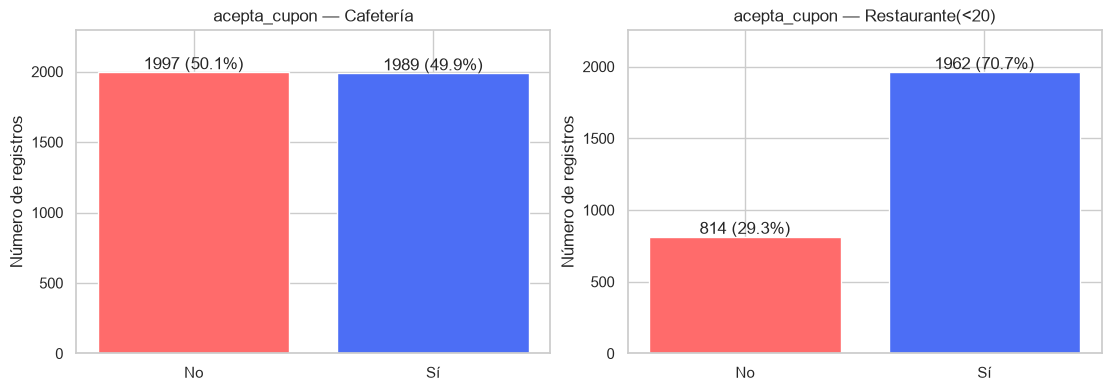

acepta_cupon,% No,% Sí
Cafetería,50.1,49.9
Restaurante(<20),29.3,70.7


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
dist_obj = {}
for ax, (c, df) in zip(axes, subconjuntos.items()):
    conteo = df['acepta_cupon'].value_counts().reindex(['No', 'Sí'])
    dist_obj[c] = (conteo / conteo.sum() * 100).round(1)
    ax.bar(conteo.index, conteo.values, color=['#FF6B6B', '#4C6EF5'])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 20, f'{v} ({v / conteo.sum() * 100:.1f}%)', ha='center')
    ax.set(title=f'acepta_cupon — {c}', ylabel='Número de registros', ylim=(0, conteo.max() * 1.15))
plt.show()

pd.DataFrame(dist_obj).T.rename(columns=lambda x: f'% {x}')

**Hallazgo.**
- **Cafetería** está prácticamente **balanceado** (≈50/50).
- **Restaurante(<20)** está **desbalanceado** (≈71% *Sí* / 29% *No*). La **clase minoritaria es “No” (rechaza el cupón)**. Esto es importante: un modelo que prediga casi siempre *Sí* tendrá una exactitud alta pero no servirá para identificar a quién *no* conviene enviarle el cupón (el caso de notificaciones molestas). Por eso se usará F1-macro como métrica de selección y se analizará el recall de la clase *No* (punto 6).

## 1.2 Completitud (valores faltantes)

,% nulos Cafetería,% nulos Restaurante(<20)
vehiculo,99.07,99.10
frecuencia_bar,0.93,0.83
frecuencia_cafeteria,1.81,1.69
frecuencia_comida_para_llevar,1.43,1.22
frecuencia_restaurante_menos_20,1.25,0.97
frecuencia_restaurante_20_a_50,1.38,1.55


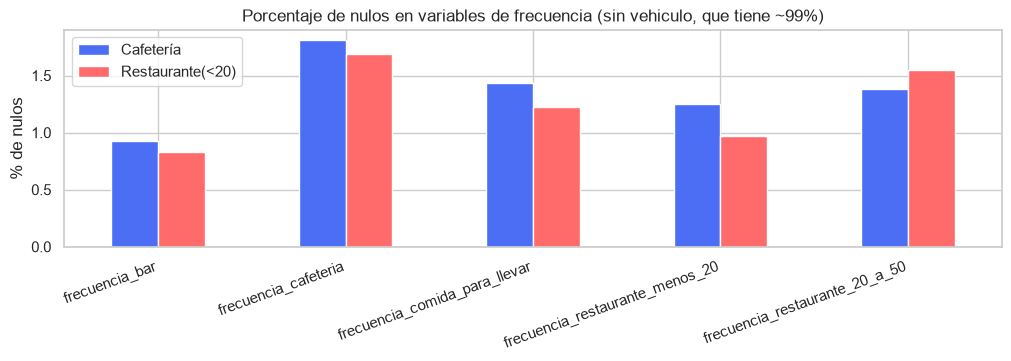

In [8]:
nulos = pd.DataFrame({c: df.isna().mean() * 100 for c, df in subconjuntos.items()}).round(2)
nulos = nulos[(nulos > 0).any(axis=1)]
display(nulos.rename(columns=lambda x: f'% nulos {x}'))

fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
nulos.drop(index='vehiculo').plot(kind='bar', ax=ax, color=['#4C6EF5', '#FF6B6B'])
ax.set(ylabel='% de nulos', title='Porcentaje de nulos en variables de frecuencia (sin vehiculo, que tiene ~99%)')
plt.xticks(rotation=20, ha='right')
plt.show()

**Hallazgo.**
- `vehiculo` tiene **~99% de valores faltantes** en ambos subconjuntos (y 100% en el archivo de prueba). No es recuperable.
- Las variables `frecuencia_*` tienen entre **1% y 2%** de faltantes: un porcentaje bajo que se puede imputar.
- El resto de variables está completo.

## 1.3 Unicidad (registros duplicados)

In [9]:
pd.DataFrame({
    'duplicados': {c: df.duplicated().sum() for c, df in subconjuntos.items()},
    '% del subconjunto': {c: round(df.duplicated().mean() * 100, 2) for c, df in subconjuntos.items()},
})

,duplicados,% del subconjunto
Cafetería,7,0.18
Restaurante(<20),7,0.25


**Hallazgo.** Hay 7 filas exactamente duplicadas en cada subconjunto (<0.3%). No existe un identificador de conductor, por lo que no se puede confirmar si son el mismo registro; sin embargo, dejarlas permitiría que una copia quede en *train* y otra en *test*, inflando las métricas.

## 1.4 Validez (valores dentro del dominio del diccionario)

Se compara el conjunto de valores observados de cada variable contra los valores permitidos según el diccionario.

In [10]:
FREC = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']
DOMINIOS = {
    'destino': ['Casa', 'Sin lugar urgente', 'Trabajo'],
    'acompanante': ['Solo', 'Amigo(s)', 'Hijo(s)', 'Pareja'],
    'clima': ['Soleado', 'Lluvioso', 'Nevado'],
    'temperatura': [30, 55, 80],
    'hora': ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.'],
    'vigencia_cupon': ['2 horas', '1 día'],
    'genero': ['Femenino', 'Masculino'],
    'edad': ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más'],
    'estado_civil': ['Soltero(a)', 'Casado(a)', 'Unión libre', 'Divorciado(a)', 'Viudo(a)'],
    'tiene_hijos': ['Sí', 'No'],
    'educacion': ['Bachillerato incompleto', 'Bachillerato completo', 'Estudios universitarios sin título',
                  'Técnico/Tecnólogo', 'Pregrado', 'Posgrado (Maestría o Doctorado)'],
    'ingreso': ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499', '$87.500 - $99.999',
                '$100.000 o más'],
    'vehiculo': ['Mazda5', 'Scooter o motocicleta', 'Camioneta tipo crossover',
                 'Carro muy viejo para instalarle Onstar', 'No conduce'],
    'frecuencia_bar': FREC, 'frecuencia_cafeteria': FREC, 'frecuencia_comida_para_llevar': FREC,
    'frecuencia_restaurante_menos_20': FREC, 'frecuencia_restaurante_20_a_50': FREC,
    'tiempo_cupon_mayor_5min': ['Sí', 'No'], 'tiempo_cupon_mayor_15min': ['Sí', 'No'],
    'tiempo_cupon_mayor_25min': ['Sí', 'No'], 'misma_direccion': ['Sí', 'No'],
    'direccion_opuesta': ['Sí', 'No'], 'acepta_cupon': ['Sí', 'No'],
}

filas = []
for c, df in subconjuntos.items():
    for col, dominio in DOMINIOS.items():
        fuera = set(df[col].dropna().unique()) - set(dominio)
        filas.append({'subconjunto': c, 'variable': col, 'n únicos': df[col].nunique(),
                      'valores fuera del dominio': ', '.join(map(str, fuera)) if fuera else '—'})
validez = pd.DataFrame(filas)
validez[validez['valores fuera del dominio'] != '—']

,subconjunto,variable,n únicos,valores fuera del dominio
12,Cafetería,vehiculo,5,Carro muy viejo para instalarle Onstar :D
36,Restaurante(<20),vehiculo,5,Carro muy viejo para instalarle Onstar :D


In [11]:
print('Variables con un único valor (constantes):')
for c, df in subconjuntos.items():
    print(f'  {c}:', [col for col in df.columns if df[col].nunique() == 1])
print('\nNúmero de ocupaciones distintas:', data['ocupacion'].nunique())

Variables con un único valor (constantes):
  Cafetería: ['cupon', 'tiempo_cupon_mayor_5min']
  Restaurante(<20): ['cupon', 'tiempo_cupon_mayor_5min']

Número de ocupaciones distintas: 25


**Hallazgo.**
- Las variables con dominio explícito en la tabla están dentro del dominio esperado, salvo una diferencia de texto en `vehiculo` (`"... Onstar :D"`), que de todas formas es una variable casi vacía.
- `tiempo_cupon_mayor_5min` es **constante** ("Sí" en todos los registros): no aporta información. `cupon` también es constante dentro de cada subconjunto, por construcción.
- `ocupacion` tiene 25 categorías, algunas con muy pocos registros (ver 1.6).

## 1.5 Consistencia entre variables

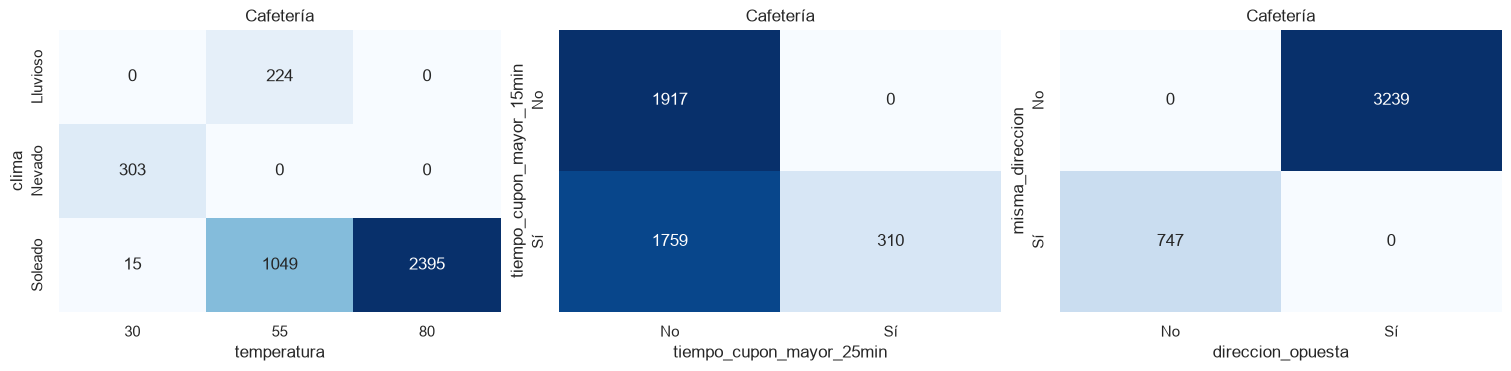

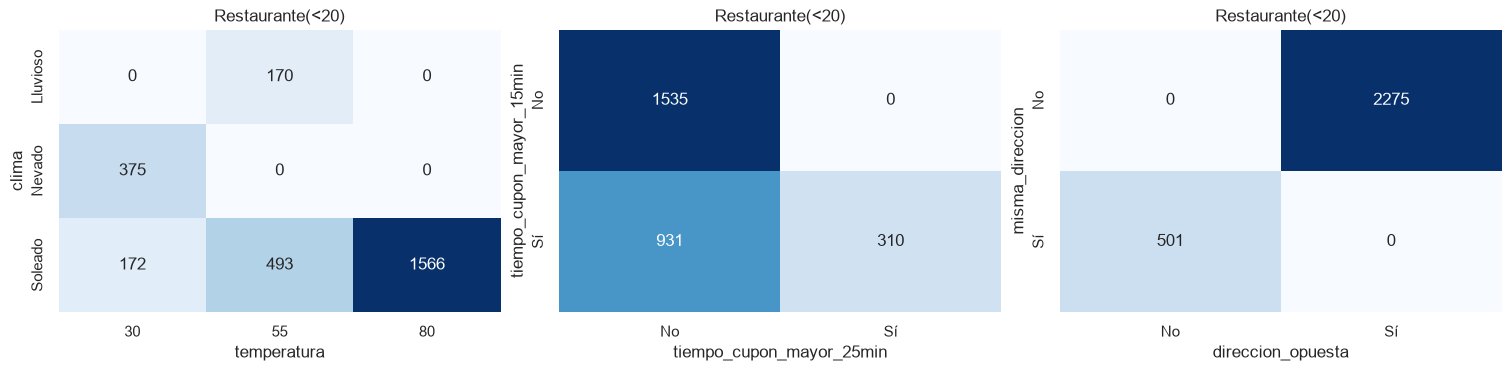

,>25 min sin >15 min,Direcciones no complementarias,Nevado a 80°F
Cupón,,,
Cafetería,0,0,0
Restaurante(<20),0,0,0


In [12]:
consistencia = []
for c, df in subconjuntos.items():
    consistencia.append({'Cupón': c,
        '>25 min sin >15 min': ((df['tiempo_cupon_mayor_25min'] == 'Sí') & (df['tiempo_cupon_mayor_15min'] == 'No')).sum(),
        'Direcciones no complementarias': (df['misma_direccion'] == df['direccion_opuesta']).sum(),
        'Nevado a 80°F': ((df['clima'] == 'Nevado') & (df['temperatura'] == 80)).sum()})
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), constrained_layout=True)
    for ax, (a, b) in zip(axes, [('clima', 'temperatura'), ('tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min'), ('misma_direccion', 'direccion_opuesta')]):
        sns.heatmap(pd.crosstab(df[a], df[b]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
        ax.set_title(c)
    plt.show()
display(pd.DataFrame(consistencia).set_index('Cupón'))
df_c = subconjuntos['Cafetería']

**Hallazgo.**
- `clima` y `temperatura` son **lógicamente consistentes** (no hay "Nevado" a 80°F), pero `temperatura` tiene redundancia parcial con `clima`: Lluvioso → 55°F, Nevado → 30°F. Solo aporta información adicional dentro de "Soleado". El diccionario aclara además que es una *variable de diseño* de la encuesta con solo 3 valores.
- `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` son consistentes (no existe >25 min sin >15 min). Juntas codifican tres niveles de distancia.
- `direccion_opuesta` es **exactamente el complemento** de `misma_direccion`: redundancia perfecta.

Para cuantificar la redundancia entre todas las variables se calcula la **V de Cramér** (asociación entre variables categóricas, de 0 a 1).

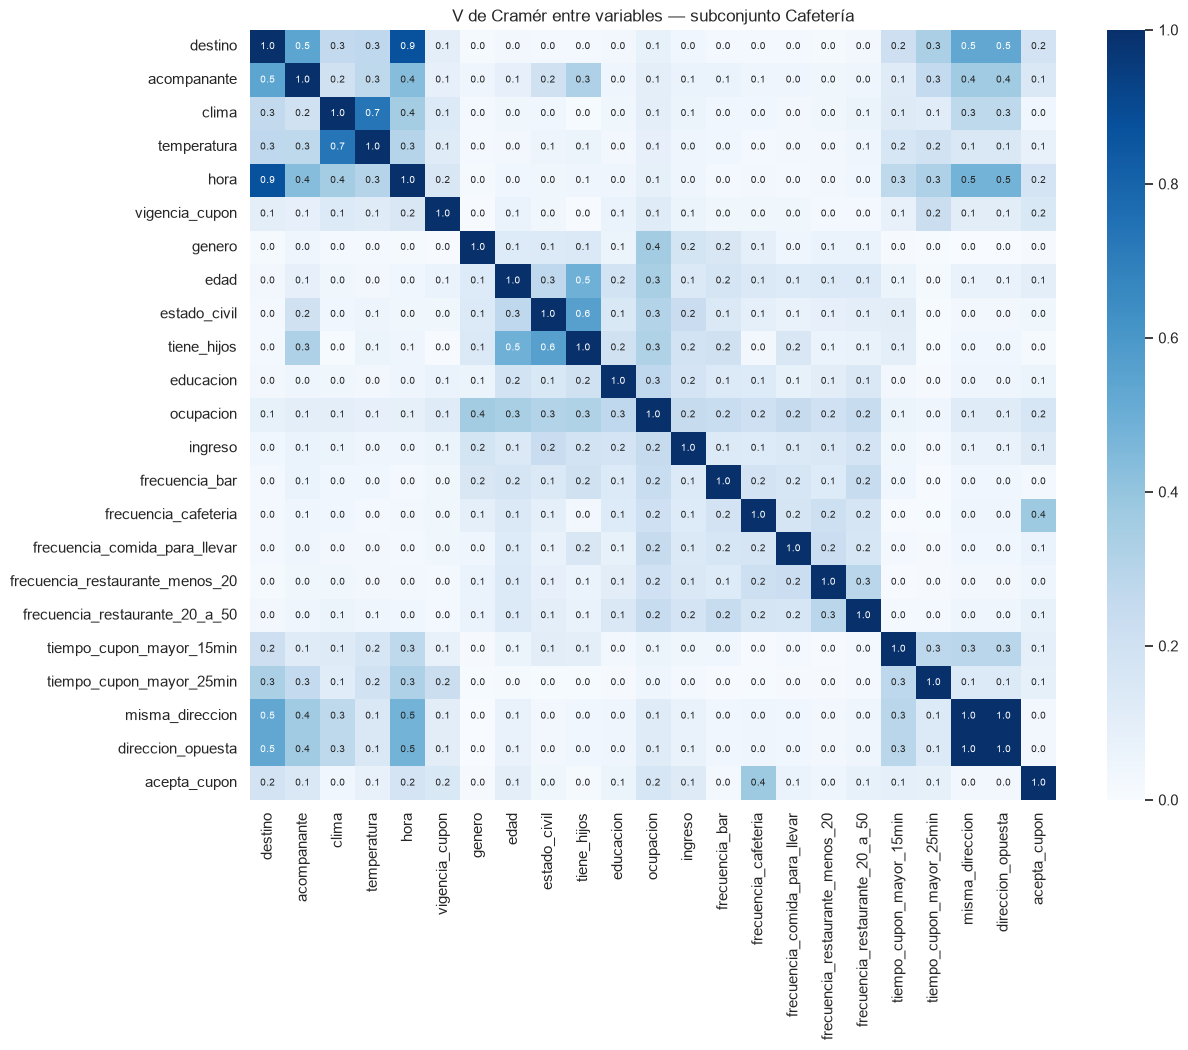

V de Cramér
misma_direccion direccion_opuesta        1.000
destino         hora                     0.873
clima           temperatura              0.732
estado_civil    tiene_hijos              0.561
destino         acompanante              0.540
                direccion_opuesta        0.529
                misma_direccion          0.529
edad            tiene_hijos              0.492
hora            direccion_opuesta        0.477
                misma_direccion          0.477

In [13]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    if min(tabla.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(tabla, correction=False)[0]
    n = tabla.values.sum()
    return np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))

cols_v = [c for c in df_c.columns if c not in ['cupon', 'vehiculo', 'tiempo_cupon_mayor_5min']]
matriz_v = pd.DataFrame(index=cols_v, columns=cols_v, dtype=float)
for a in cols_v:
    for b in cols_v:
        matriz_v.loc[a, b] = cramers_v(df_c[a], df_c[b])

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(matriz_v, cmap='Blues', vmin=0, vmax=1, ax=ax, annot=True, fmt='.1f', annot_kws={'size': 7})
ax.set_title('V de Cramér entre variables — subconjunto Cafetería')
plt.show()

pares = (matriz_v.where(np.triu(np.ones(matriz_v.shape, dtype=bool), k=1)).stack()
         .sort_values(ascending=False).head(10).round(3).to_frame('V de Cramér'))
pares

**Hallazgo.** Las asociaciones más altas confirman las redundancias: `misma_direccion`–`direccion_opuesta` (V = 1) y `clima`–`temperatura` (V ≈ 0.73). Aparece además una asociación fuerte `destino`–`hora` (V ≈ 0.87), producto del diseño de la encuesta (por ejemplo, ir al trabajo ocurre a las 7 a.m.). Se conservan ambas porque no son idénticas y cada una describe un aspecto distinto del escenario, pero es una fuente de redundancia que se discute en el análisis. Las asociaciones del perfil (`estado_civil`–`tiene_hijos`, `edad`–`tiene_hijos`) son esperables y tampoco se eliminan.

## 1.6 Valores atípicos y categorías poco frecuentes

La única variable numérica es `temperatura`, que solo toma 3 valores fijos ({30, 55, 80}); no tiene atípicos en el sentido clásico (IQR). En variables categóricas, el equivalente son las **categorías con muy pocos registros**, que pueden generar coeficientes inestables o reglas poco confiables.

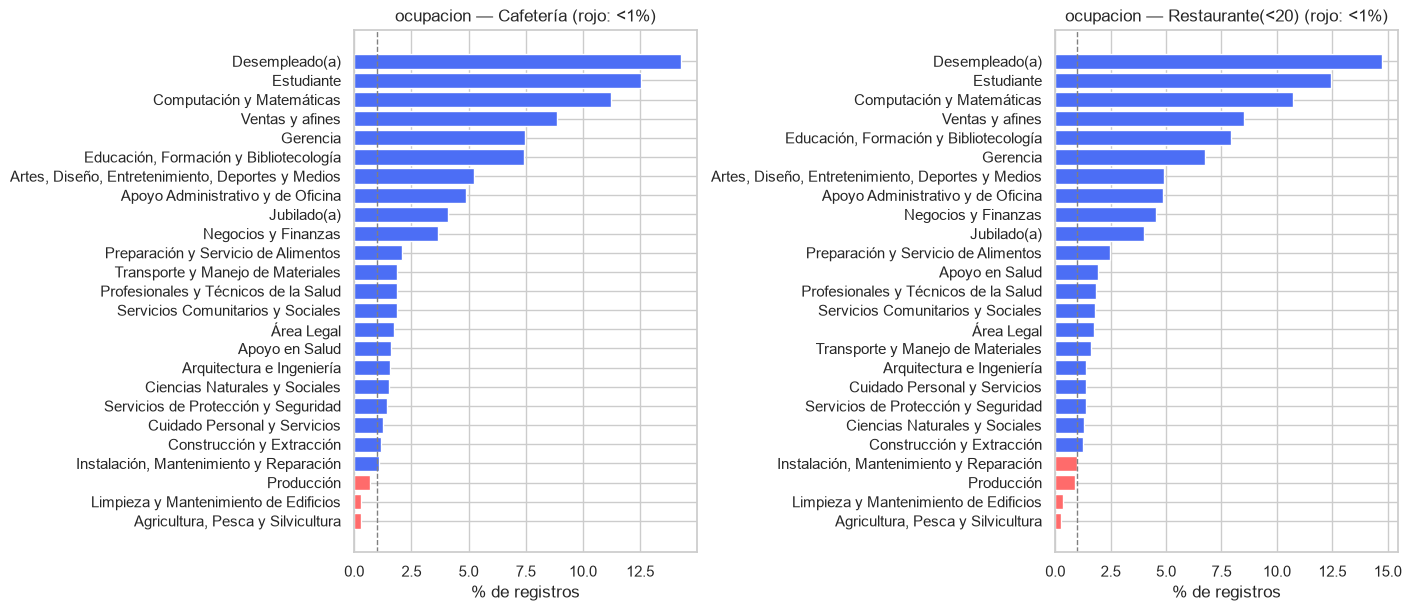

,# categorías con <1% (Cafetería),# categorías con <1% (Restaurante(<20))
estado_civil,1,0
educacion,1,1
ocupacion,3,4


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, (c, df) in zip(axes, subconjuntos.items()):
    vc = df['ocupacion'].value_counts(normalize=True).sort_values() * 100
    ax.barh(vc.index, vc.values, color=np.where(vc.values < 1, '#FF6B6B', '#4C6EF5'))
    ax.axvline(1, color='gray', ls='--', lw=1)
    ax.set(title=f'ocupacion — {c} (rojo: <1%)', xlabel='% de registros')
plt.show()

raras = {c: {col: (df[col].value_counts(normalize=True) < 0.01).sum()
             for col in df.columns if pd.api.types.is_string_dtype(df[col]) and df[col].nunique() > 2}
         for c, df in subconjuntos.items()}
raras = pd.DataFrame(raras)
raras[(raras > 0).any(axis=1)].rename(columns=lambda x: f'# categorías con <1% ({x})')

**Hallazgo.** Hay categorías poco frecuentes (algunas ocupaciones, `Viudo(a)`, `Bachillerato incompleto`), pero son valores **válidos** del dominio y no errores. No se eliminan: el One-Hot con `handle_unknown='ignore'` y la regularización (en logística) o `min_samples_leaf` (en árboles) mitigan parcialmente su efecto. Ignorar categorías desconocidas permite predecir, pero no aprende su comportamiento; las categorías raras siguen teniendo mayor incertidumbre.

## 1.7 Relación de las variables con la aceptación del cupón

Tasa de aceptación (% de *Sí*) por categoría, comparando ambos tipos de cupón. La línea punteada marca la tasa global de cada subconjunto.

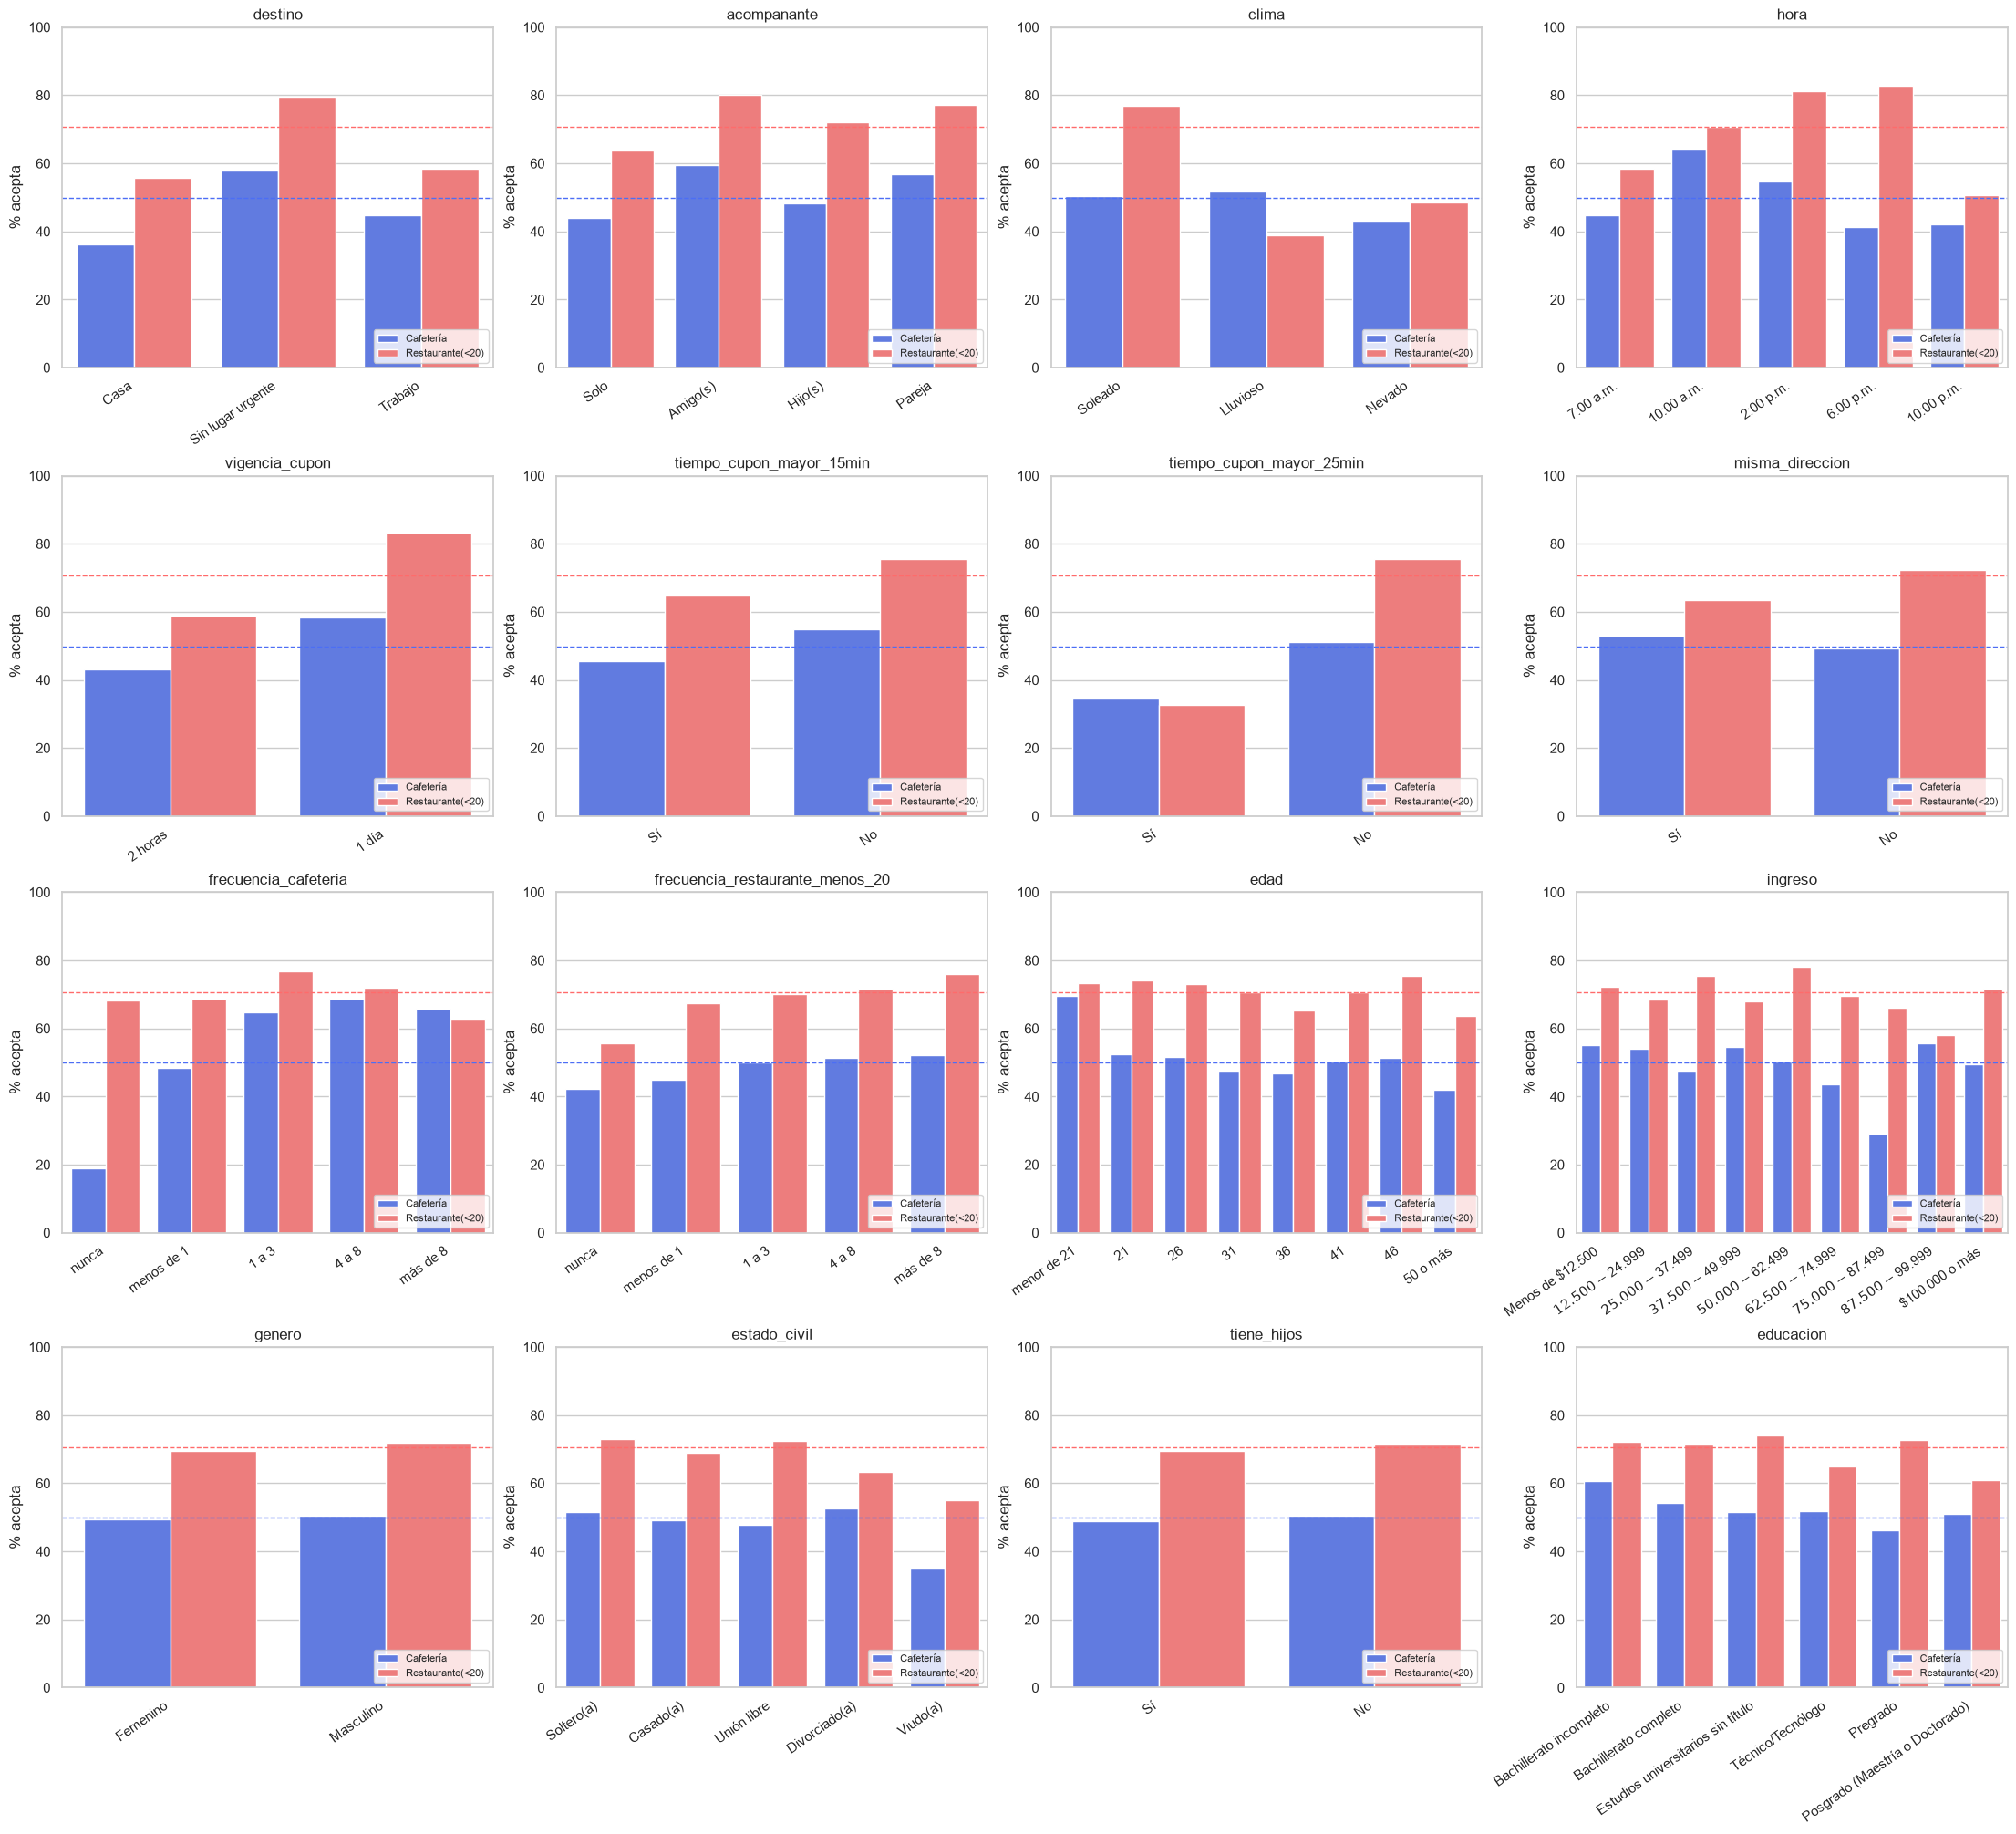

In [15]:
vars_plot = ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon', 'tiempo_cupon_mayor_15min',
             'tiempo_cupon_mayor_25min', 'misma_direccion', 'frecuencia_cafeteria',
             'frecuencia_restaurante_menos_20', 'edad', 'ingreso', 'genero', 'estado_civil', 'tiene_hijos', 'educacion']
ambos = pd.concat(subconjuntos.values())
ambos['acepta'] = (ambos['acepta_cupon'] == 'Sí').astype(int)

fig, axes = plt.subplots(4, 4, figsize=(22, 20), constrained_layout=True)
for ax, var in zip(axes.flat, vars_plot):
    orden = [v for v in DOMINIOS[var] if v in ambos[var].unique()]
    tasa = ambos.groupby(['cupon', var])['acepta'].mean().mul(100).reset_index()
    sns.barplot(data=tasa, x=var, y='acepta', hue='cupon', order=orden, hue_order=CUPONES,
                palette=['#4C6EF5', '#FF6B6B'], ax=ax)
    for color, c in zip(['#4C6EF5', '#FF6B6B'], CUPONES):
        ax.axhline(ambos.loc[ambos['cupon'] == c, 'acepta'].mean() * 100, color=color, ls='--', lw=1)
    ax.set(title=var, xlabel='', ylabel='% acepta', ylim=(0, 100))
    ax.tick_params(axis='x', rotation=35)
    for lbl in ax.get_xticklabels():
        lbl.set_ha('right')
    ax.legend(fontsize=8, loc='lower right')
plt.show()

**Hallazgos exploratorios (a confirmar con los modelos):**
- **Contexto común a ambos cupones:** `destino` = "Sin lugar urgente" (58% / 79% de aceptación vs 36% / 56% yendo a casa), ir acompañado de amigos o pareja (vs solo), vigencia de 1 día (vs 2 horas) y que el lugar quede a **menos de 25 minutos** aumentan la aceptación.
- **Cafetería:** el factor más marcado es el **hábito**: quienes *nunca* van a cafeterías aceptan solo el 18.8%, frente a ~65% de quienes van 1 o más veces al mes. La hora también influye (64% a las 10 a.m. vs ~41% a las 6 p.m. y 10 p.m.). El clima casi no cambia la aceptación.
- **Restaurante(<20):** depende más del **contexto** que del hábito. Clima (77% soleado vs 39% lluvioso), hora (≈82% a las 2 p.m. y 6 p.m. vs 51% a las 10 p.m.) y distancia (75% → 33% si queda a más de 25 min). La frecuencia de visita a restaurantes <$20 casi no discrimina, salvo "nunca". Curiosamente, que quede en la *misma dirección* no aumenta la aceptación (64% vs 72%), posiblemente por la interacción con destino y hora del diseño de la encuesta.
- **Demografía:** el `genero` casi no cambia la aceptación. `edad` (menores de 21 aceptan más café) e `ingreso` muestran diferencias no monótonas y moderadas. Este punto se retoma en el análisis de sesgo.

En Restaurante(<20) las tasas deben compararse con su base de aceptación cercana al 71%, no con 50%. Las gráficas describen asociaciones, no efectos causales. Esta exploración general precede a la partición, como en las prácticas, y no se usa para ajustar hiperparámetros. Sin identificador de conductor no se puede descartar que una misma persona aporte escenarios a train y test.

# 2. Limpieza y preparación de los datos

Decisiones tomadas por el equipo, a partir de los hallazgos del paso 1:

| # | Decisión | Justificación (hallazgo) |
|---|---|---|
| 1 | **Eliminar `vehiculo`** | ~99% nulos en entrenamiento y 100% en prueba (1.2). No es imputable de forma confiable. |
| 2 | **Eliminar `tiempo_cupon_mayor_5min`** | Constante (1.4): varianza cero, no aporta información. |
| 3 | **Eliminar `direccion_opuesta`** | Complemento exacto de `misma_direccion` (1.5, V de Cramér = 1). Redundancia perfecta. |
| 4 | **Eliminar `temperatura`** | Variable de diseño de la encuesta, parcialmente asociada con `clima` (1.5). Se conserva `clima`, que es más interpretable. |
| 5 | **Eliminar `cupon`** | Constante dentro de cada subconjunto (cada modelo es de un solo tipo de cupón). |
| 6 | **Eliminar duplicados exactos** | 7 por subconjunto (1.3). Evita que copias queden en train y test simultáneamente. |
| 7 | **Imputar con la moda (`most_frequent`) dentro del pipeline** las `frecuencia_*` | 1–2% de faltantes (1.2). Imputar dentro del pipeline evita fuga de información (la moda se aprende solo con el fold de entrenamiento) y permite procesar datos nuevos con faltantes. |
| 8 | **`OrdinalEncoder` con el orden del diccionario** para `edad`, `educacion`, `ingreso`, `hora` y las 5 `frecuencia_*` | Son ordinales (diccionario): el orden tiene significado y se reduce la dimensionalidad frente a One-Hot. |
| 9 | **`OneHotEncoder(drop='if_binary', handle_unknown='ignore')`** para las nominales | `destino`, `acompanante`, `clima`, `estado_civil`, `ocupacion` no tienen orden. Las binarias quedan en una sola columna. `handle_unknown='ignore'` protege ante categorías nuevas en prueba. |
| 10 | **`StandardScaler` solo para regresión logística** | La regularización L1/L2 penaliza coeficientes y es sensible a la escala. Los árboles y Random Forest son invariantes a la escala. |
| 11 | **Partición 80/20 estratificada** y **`StratifiedKFold(5)`** | La estratificación conserva la proporción de clases (clave en Restaurante(<20)). 5 folds es un buen compromiso entre estabilidad y costo de cómputo. |
| 12 | **Métrica de selección: F1-macro** | Promedia el F1 de *Sí* y *No*. No premia predecir siempre la clase mayoritaria en Restaurante(<20). |
| 13 | **Variable objetivo: `Sí` → 1, `No` → 0** | La clase positiva (1) es *acepta el cupón*. |

**Alcance de las decisiones.** Se conserva la eliminación de temperatura registrada por el equipo, aunque su redundancia es parcial: se pierde información dentro de clima soleado. Codificar ordinales supone niveles equidistantes en la regresión logística (también para la hora); los árboles pueden capturar relaciones no monótonas. No se ajustarán estas decisiones después de mirar test.

In [16]:
COLS_ELIMINAR = ['vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta', 'temperatura', 'cupon']

COLS_ORDINALES = ['edad', 'educacion', 'ingreso', 'hora', 'frecuencia_bar', 'frecuencia_cafeteria',
                  'frecuencia_comida_para_llevar', 'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50']
COLS_NOMINALES = ['destino', 'acompanante', 'clima', 'vigencia_cupon', 'genero', 'estado_civil', 'tiene_hijos',
                  'ocupacion', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion']
ORDEN_ORDINALES = [DOMINIOS[c] for c in COLS_ORDINALES]


def preparar(df):
    # Elimina duplicados exactos (sobre el registro original) y las columnas descartadas
    df = df.drop_duplicates().reset_index(drop=True)
    X = df.drop(columns=COLS_ELIMINAR + ['acepta_cupon'])
    assert df['acepta_cupon'].isin(['Sí', 'No']).all()
    y = (df['acepta_cupon'] == 'Sí').astype(int)
    return X, y


splits = {}
for c, df in subconjuntos.items():
    X, y = preparar(df)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
    splits[c] = (X_train, X_test, y_train, y_test)
    print(f'{c:<18} train: {X_train.shape}  test: {X_test.shape}  '
          f'% Sí train: {y_train.mean() * 100:.1f}  % Sí test: {y_test.mean() * 100:.1f}')

assert set(COLS_ORDINALES + COLS_NOMINALES) == set(X.columns)

Cafetería          train: (3183, 20)  test: (796, 20)  % Sí train: 49.8  % Sí test: 49.9
Restaurante(<20)   train: (2215, 20)  test: (554, 20)  % Sí train: 70.7  % Sí test: 70.8


### Pipeline de preprocesamiento

Se sigue el patrón de `ColumnTransformer` y `Pipeline` de P7 y P8, usando `imblearn` para incorporar el balanceo de P9:

`imputación por moda → [SMOTEN, solo sección 6] → ordinales → escalado (logística) + One-Hot → modelo`.

Cada transformación se ajusta dentro del fold de entrenamiento. SMOTEN recibe categorías originales e imputadas, antes de codificarlas; así no interpola edades o frecuencias como si fueran medidas continuas. La caché solo reutiliza pasos con los mismos datos y parámetros, sin compartir ajustes entre folds distintos.

In [17]:
def crear_pipeline(modelo, escalar=False, balanceo=False):
    imputador = SimpleImputer(strategy='most_frequent').set_output(transform='pandas')

    ordinal = ColumnTransformer(
        [('ord', OrdinalEncoder(categories=ORDEN_ORDINALES), COLS_ORDINALES)],
        remainder='passthrough', verbose_feature_names_out=False,
    ).set_output(transform='pandas')

    preprocesador = ColumnTransformer([
        ('ord', StandardScaler() if escalar else 'passthrough', COLS_ORDINALES),
        ('nom', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), COLS_NOMINALES),
    ])

    pasos = [('imputador', imputador)]
    if balanceo:
        pasos.append(('balanceo', SMOTEN(random_state=RANDOM_STATE)))
    pasos += [('ordinal', ordinal), ('preprocesador', preprocesador), ('modelo', modelo)]
    return ImbPipeline(pasos, memory=CACHE)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
crear_pipeline(LogisticRegression(), escalar=True)

,steps,"[('imputador', ...), ('ordinal', ...), ...]"
,memory,Memory(locati...peline/joblib)
,transform_input,None
,verbose,False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ord', ...)]"


In [18]:
def metricas(y_true, y_pred):
    return {
        'Precisión (Sí)': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Recall (Sí)': recall_score(y_true, y_pred, pos_label=1),
        'F1 (Sí)': f1_score(y_true, y_pred, pos_label=1),
        'Precisión (No)': precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        'Recall (No)': recall_score(y_true, y_pred, pos_label=0),
        'F1 (No)': f1_score(y_true, y_pred, pos_label=0),
        'F1-macro': f1_score(y_true, y_pred, average='macro'),
    }


def buscar(pipeline, param_grid, cupon):
    X_train, X_test, y_train, y_test = splits[cupon]
    grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1_macro', n_jobs=N_JOBS, return_train_score=True, error_score='raise')
    print(f'Buscando {type(pipeline.named_steps["modelo"]).__name__} — {cupon}', flush=True)
    with parallel_config(max_nbytes=None):
        grid.fit(X_train, y_train)
    return grid


def resumen_grid(grid, cols_param, top=8):
    res = pd.DataFrame(grid.cv_results_)
    cols = [f'param_{p}' for p in cols_param] + ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
    return (res[cols].sort_values('rank_test_score').head(top)
            .rename(columns=lambda x: x.replace('param_modelo__', '')).round(4))


def evaluar(grid, cupon, nombre):
    X_train, X_test, y_train, y_test = splits[cupon]
    modelo = grid.best_estimator_
    y_pred_tr, y_pred_te = modelo.predict(X_train), modelo.predict(X_test)
    print(f'=== {nombre} — {cupon} ===')
    print('Mejores hiperparámetros:', grid.best_params_)
    print(f'F1-macro CV: {grid.best_score_:.4f}')
    tabla = pd.DataFrame({'Train': metricas(y_train, y_pred_tr), 'Test': metricas(y_test, y_pred_te)}).T.round(4)
    display(tabla)
    print(classification_report(y_test, y_pred_te, target_names=['No', 'Sí']))
    return metricas(y_test, y_pred_te)


def matrices(grids, nombre):
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), constrained_layout=True)
    for ax, c in zip(axes, CUPONES):
        X_train, X_test, y_train, y_test = splits[c]
        ConfusionMatrixDisplay.from_predictions(y_test, grids[c].predict(X_test), display_labels=['No', 'Sí'],
                                                cmap='Blues', ax=ax, colorbar=False)
        ax.set_title(f'{nombre} — {c}')
    plt.show()


resultados_test = {}  # (cupón, modelo) -> métricas en test

# 3. Regresión logística

Pipeline: imputación → codificación ordinal → `StandardScaler` (ordinales) + One-Hot (nominales) → `LogisticRegression`.

**Búsqueda de hiperparámetros** (`GridSearchCV`, 5 folds estratificados, F1-macro):
- **Tipo de regularización**: L2, L1 y ElasticNet (mezcla 50/50). En scikit-learn 1.9 el parámetro `penalty` está obsoleto y la regularización se controla con `l1_ratio` (0 = L2, 1 = L1, 0.5 = ElasticNet).
- **Solver**: `lbfgs`, `newton-cg`, `liblinear` y `saga`. Solo se prueban las combinaciones válidas: L1 únicamente con `liblinear`/`saga` y ElasticNet únicamente con `saga`.
- **C** (inverso de la fuerza de regularización): 0.01, 0.1, 1 y 10.

In [19]:
C_VALORES = [0.01, 0.1, 1, 10]
param_grid_rl = [
    {'modelo__l1_ratio': [0.0], 'modelo__solver': ['lbfgs', 'newton-cg', 'liblinear', 'saga'], 'modelo__C': C_VALORES},
    {'modelo__l1_ratio': [1.0], 'modelo__solver': ['liblinear', 'saga'], 'modelo__C': C_VALORES},
    {'modelo__l1_ratio': [0.5], 'modelo__solver': ['saga'], 'modelo__C': C_VALORES},
]

grids_rl = {}
for c in CUPONES:
    pipe = crear_pipeline(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), escalar=True)
    grids_rl[c] = buscar(pipe, param_grid_rl, c)

Buscando LogisticRegression — Cafetería


Buscando LogisticRegression — Restaurante(<20)


In [20]:
for c in CUPONES:
    display(Markdown(f'**Top combinaciones — Regresión logística — {c}**'))
    display(resumen_grid(grids_rl[c], ['modelo__l1_ratio', 'modelo__solver', 'modelo__C']))

**Top combinaciones — Regresión logística — Cafetería**

,l1_ratio,solver,C,mean_train_score,mean_test_score,std_test_score,rank_test_score
5,0.0,newton-cg,0.1,0.7238,0.7134,0.0173,1
7,0.0,saga,0.1,0.7238,0.7134,0.0173,1
4,0.0,lbfgs,0.1,0.7239,0.7131,0.0175,3
6,0.0,liblinear,0.1,0.7232,0.7122,0.0182,4
21,1.0,saga,1.0,0.7227,0.7090,0.0184,5
20,1.0,liblinear,1.0,0.7228,0.7090,0.0184,6
9,0.0,newton-cg,1.0,0.7238,0.7084,0.0187,7
11,0.0,saga,1.0,0.7237,0.7084,0.0187,7


**Top combinaciones — Regresión logística — Restaurante(<20)**

,l1_ratio,solver,C,mean_train_score,mean_test_score,std_test_score,rank_test_score
13,0.0,newton-cg,10.0,0.6674,0.6540,0.0177,1
15,0.0,saga,10.0,0.6674,0.6540,0.0177,1
14,0.0,liblinear,10.0,0.6674,0.6540,0.0177,1
12,0.0,lbfgs,10.0,0.6671,0.6540,0.0177,1
27,0.5,saga,10.0,0.6671,0.6540,0.0177,1
23,1.0,saga,10.0,0.6671,0.6531,0.0180,6
22,1.0,liblinear,10.0,0.6672,0.6531,0.0180,6
9,0.0,newton-cg,1.0,0.6665,0.6525,0.0129,8


=== Regresión logística — Cafetería ===
Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__l1_ratio': 0.0, 'modelo__solver': 'newton-cg'}
F1-macro CV: 0.7134


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.7213,0.7213,0.7213,0.7232,0.7232,0.7232,0.7223
Test,0.6824,0.6927,0.6875,0.6896,0.6792,0.6843,0.6859


              precision    recall  f1-score   support

          No       0.69      0.68      0.68       399
          Sí       0.68      0.69      0.69       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796

=== Regresión logística — Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__C': 10, 'modelo__l1_ratio': 0.0, 'modelo__solver': 'lbfgs'}
F1-macro CV: 0.6540


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.7837,0.9202,0.8465,0.6667,0.3858,0.4888,0.6676
Test,0.7810,0.9005,0.8365,0.6176,0.3889,0.4773,0.6569


              precision    recall  f1-score   support

          No       0.62      0.39      0.48       162
          Sí       0.78      0.90      0.84       392

    accuracy                           0.75       554
   macro avg       0.70      0.64      0.66       554
weighted avg       0.73      0.75      0.73       554



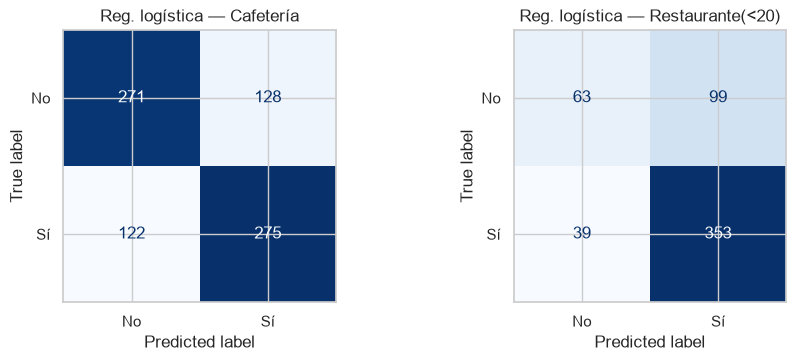

In [21]:
for c in CUPONES:
    resultados_test[(c, 'Regresión logística')] = evaluar(grids_rl[c], c, 'Regresión logística')
matrices(grids_rl, 'Reg. logística')

**Análisis — Regresión logística.**

- **Cafetería:** se seleccionó `C=0.1, l1_ratio=0.0, solver=newton-cg`. F1-macro: **0.713 en CV**, 0.722 en train y **0.686 en test**. El recall de No fue 0.679.
- **Restaurante(<20):** se seleccionó `C=10, l1_ratio=0.0, solver=lbfgs`. F1-macro: **0.654 en CV**, 0.668 en train y **0.657 en test**. El recall de No fue 0.389.

La regularización limita los coeficientes; un C pequeño penaliza más. Este modelo ofrece una referencia interpretable, pero su relación lineal en log-odds y la codificación ordinal restringen las interacciones que puede aprender. En Restaurante, el recall de No permite ver errores que el F1 positivo por sí solo oculta.

# 4. Árboles de decisión

Pipeline: imputación → codificación ordinal → One-Hot (nominales) → `DecisionTreeClassifier`. No se escala porque los árboles son invariantes a transformaciones monótonas.

**Búsqueda de hiperparámetros:**
- `max_depth`: 3, 5, 7, 10, 15, None. Controla la complejidad: un árbol muy profundo memoriza el entrenamiento.
- `min_samples_leaf`: 1, 5, 10, 20, 50. Hojas más grandes producen reglas más generales y estables.
- `criterion`: gini, entropy, log_loss. Medida de impureza usada para elegir las divisiones.

In [22]:
param_grid_dt = {
    'modelo__max_depth': [3, 5, 7, 10, 15, None],
    'modelo__min_samples_leaf': [1, 5, 10, 20, 50],
    'modelo__criterion': ['gini', 'entropy', 'log_loss'],
}

grids_dt = {}
for c in CUPONES:
    pipe = crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
    grids_dt[c] = buscar(pipe, param_grid_dt, c)

for c in CUPONES:
    display(Markdown(f'**Top combinaciones — Árbol de decisión — {c}**'))
    display(resumen_grid(grids_dt[c], ['modelo__max_depth', 'modelo__min_samples_leaf', 'modelo__criterion']))

Buscando DecisionTreeClassifier — Cafetería


Buscando DecisionTreeClassifier — Restaurante(<20)


**Top combinaciones — Árbol de decisión — Cafetería**

,max_depth,min_samples_leaf,criterion,mean_train_score,mean_test_score,std_test_score,rank_test_score
69,5,50,log_loss,0.7233,0.7192,0.0183,1
39,5,50,entropy,0.7233,0.7192,0.0183,1
9,5,50,gini,0.7230,0.7180,0.0162,3
6,5,5,gini,0.7295,0.7091,0.0131,4
44,7,50,entropy,0.7264,0.7084,0.0136,5
84,15,50,log_loss,0.7264,0.7084,0.0136,5
79,10,50,log_loss,0.7264,0.7084,0.0136,5
74,7,50,log_loss,0.7264,0.7084,0.0136,5


**Top combinaciones — Árbol de decisión — Restaurante(<20)**

,max_depth,min_samples_leaf,criterion,mean_train_score,mean_test_score,std_test_score,rank_test_score
28,None,20,gini,0.7137,0.6854,0.0139,1
23,15,20,gini,0.7137,0.6854,0.0139,1
18,10,20,gini,0.7121,0.6843,0.0155,3
13,7,20,gini,0.7029,0.6732,0.0130,4
8,5,20,gini,0.6817,0.6672,0.0113,5
78,10,20,log_loss,0.7161,0.6659,0.0215,6
88,None,20,log_loss,0.7161,0.6659,0.0215,6
83,15,20,log_loss,0.7161,0.6659,0.0215,6


=== Árbol de decisión — Cafetería ===
Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 50}
F1-macro CV: 0.7192


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.7072,0.7478,0.7269,0.7344,0.6925,0.7129,0.7199
Test,0.6743,0.7406,0.7059,0.7139,0.6441,0.6772,0.6915


              precision    recall  f1-score   support

          No       0.71      0.64      0.68       399
          Sí       0.67      0.74      0.71       397

    accuracy                           0.69       796
   macro avg       0.69      0.69      0.69       796
weighted avg       0.69      0.69      0.69       796

=== Árbol de decisión — Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 15, 'modelo__min_samples_leaf': 20}
F1-macro CV: 0.6854


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.8101,0.9177,0.8606,0.7068,0.4799,0.5717,0.7161
Test,0.7837,0.9056,0.8402,0.6337,0.3951,0.4867,0.6635


              precision    recall  f1-score   support

          No       0.63      0.40      0.49       162
          Sí       0.78      0.91      0.84       392

    accuracy                           0.76       554
   macro avg       0.71      0.65      0.66       554
weighted avg       0.74      0.76      0.74       554



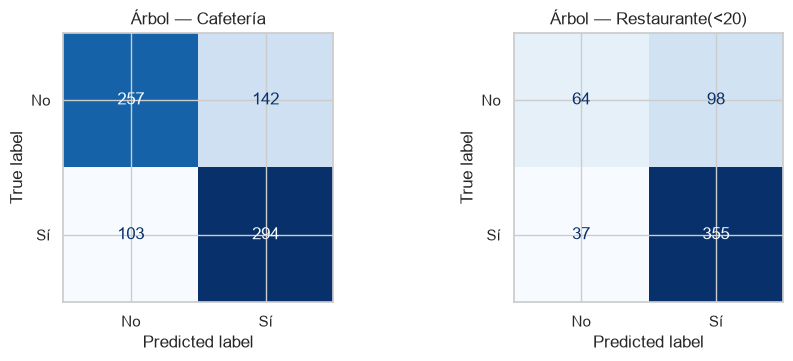

In [23]:
for c in CUPONES:
    resultados_test[(c, 'Árbol de decisión')] = evaluar(grids_dt[c], c, 'Árbol de decisión')
matrices(grids_dt, 'Árbol')

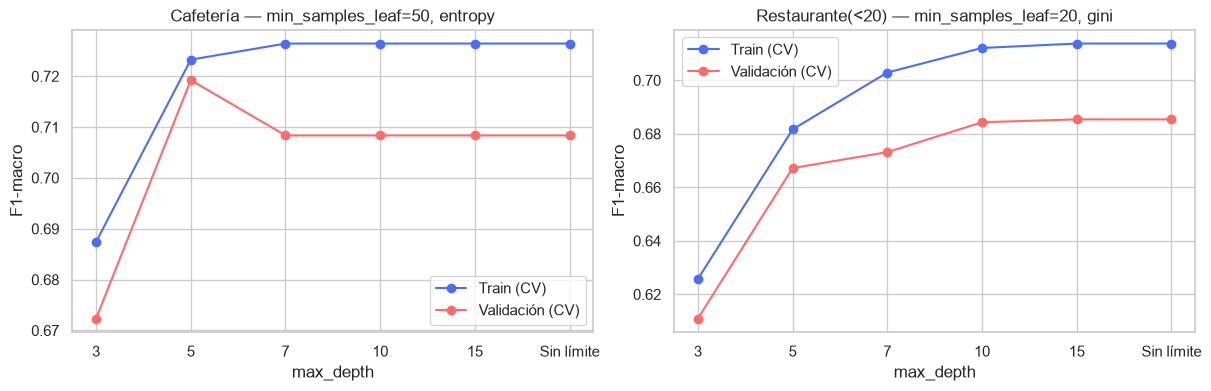

In [24]:
# Efecto de la profundidad sobre el F1-macro (train vs validación), con los demás parámetros en su mejor valor
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, c in zip(axes, CUPONES):
    res = pd.DataFrame(grids_dt[c].cv_results_)
    bp = grids_dt[c].best_params_
    sel = res[(res['param_modelo__min_samples_leaf'] == bp['modelo__min_samples_leaf'])
              & (res['param_modelo__criterion'] == bp['modelo__criterion'])].copy()
    sel['depth'] = ['Sin límite' if pd.isna(v) else str(int(v)) for v in sel['param_modelo__max_depth']]
    ax.plot(sel['depth'], sel['mean_train_score'], 'o-', label='Train (CV)', color='#4C6EF5')
    ax.plot(sel['depth'], sel['mean_test_score'], 'o-', label='Validación (CV)', color='#FF6B6B')
    ax.set(title=f'{c} — min_samples_leaf={bp["modelo__min_samples_leaf"]}, {bp["modelo__criterion"]}',
           xlabel='max_depth', ylabel='F1-macro')
    ax.legend()
plt.show()

**Análisis — Árboles de decisión.**

- **Cafetería:** se seleccionó `criterion=entropy, max_depth=5, min_samples_leaf=50`. F1-macro: **0.719 en CV**, 0.720 en train y **0.692 en test**. El recall de No fue 0.644.
- **Restaurante(<20):** se seleccionó `criterion=gini, max_depth=15, min_samples_leaf=20`. F1-macro: **0.685 en CV**, 0.716 en train y **0.663 en test**. El recall de No fue 0.395.

La profundidad y el mínimo de muestras por hoja controlan la especialización de las reglas. La curva train/CV muestra si aumentar profundidad mejora generalización o solo el ajuste al entrenamiento. Las diferencias entre train y test impiden interpretar el rendimiento de entrenamiento como desempeño esperado en producción.

# 5. Random Forest

Pipeline: imputación → codificación ordinal → One-Hot → `RandomForestClassifier` (`max_features='sqrt'`, el valor por defecto).

**Búsqueda de hiperparámetros:**
- `n_estimators`: 100, 200, 400. Más árboles reducen la varianza del ensamble, con rendimientos decrecientes.
- `max_depth`: 5, 10, 15, 20, None.
- `min_samples_leaf`: 1, 2, 5, 10.

In [25]:
param_grid_rf = {
    'modelo__n_estimators': [100, 200, 400],
    'modelo__max_depth': [5, 10, 15, 20, None],
    'modelo__min_samples_leaf': [1, 2, 5, 10],
}

grids_rf = {}
for c in CUPONES:
    pipe = crear_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1))
    grids_rf[c] = buscar(pipe, param_grid_rf, c)

for c in CUPONES:
    display(Markdown(f'**Top combinaciones — Random Forest — {c}**'))
    display(resumen_grid(grids_rf[c], ['modelo__n_estimators', 'modelo__max_depth', 'modelo__min_samples_leaf']))

Buscando RandomForestClassifier — Cafetería


Buscando RandomForestClassifier — Restaurante(<20)


**Top combinaciones — Random Forest — Cafetería**

,n_estimators,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
49,200,None,1,0.9991,0.7646,0.0082,1
50,400,None,1,0.9991,0.7633,0.0078,2
38,400,20,1,0.9991,0.7627,0.0078,3
48,100,None,1,0.9991,0.7615,0.0094,4
36,100,20,1,0.9990,0.7608,0.0045,5
24,100,15,1,0.9924,0.7592,0.0174,6
26,400,15,1,0.9947,0.7579,0.0122,7
53,400,None,2,0.9508,0.7576,0.0057,8


**Top combinaciones — Random Forest — Restaurante(<20)**

,n_estimators,max_depth,min_samples_leaf,mean_train_score,mean_test_score,std_test_score,rank_test_score
49,200,None,1,0.9992,0.7048,0.0151,1
50,400,None,1,0.9992,0.7041,0.0144,2
36,100,20,1,0.9992,0.7003,0.0056,3
48,100,None,1,0.9992,0.7003,0.0105,4
37,200,20,1,0.9992,0.6995,0.0082,5
38,400,20,1,0.9992,0.6980,0.0116,6
26,400,15,1,0.9769,0.6923,0.0146,7
25,200,15,1,0.9761,0.6899,0.0130,8


=== Random Forest — Cafetería ===
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1-macro CV: 0.7646


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.9994,0.9987,0.9991,0.9987,0.9994,0.9991,0.9991
Test,0.7687,0.7783,0.7735,0.7766,0.7669,0.7718,0.7726


              precision    recall  f1-score   support

          No       0.78      0.77      0.77       399
          Sí       0.77      0.78      0.77       397

    accuracy                           0.77       796
   macro avg       0.77      0.77      0.77       796
weighted avg       0.77      0.77      0.77       796

=== Random Forest — Restaurante(<20) ===
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
F1-macro CV: 0.7048


,Precisión (Sí),Recall (Sí),F1 (Sí),Precisión (No),Recall (No),F1 (No),F1-macro
Train,0.9994,0.9994,0.9994,0.9985,0.9985,0.9985,0.9989
Test,0.7927,0.9362,0.8585,0.7253,0.4074,0.5217,0.6901


              precision    recall  f1-score   support

          No       0.73      0.41      0.52       162
          Sí       0.79      0.94      0.86       392

    accuracy                           0.78       554
   macro avg       0.76      0.67      0.69       554
weighted avg       0.77      0.78      0.76       554



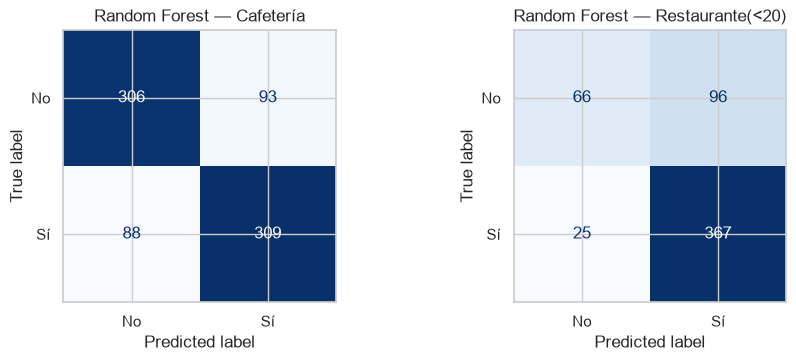

In [26]:
for c in CUPONES:
    resultados_test[(c, 'Random Forest')] = evaluar(grids_rf[c], c, 'Random Forest')
matrices(grids_rf, 'Random Forest')

**Análisis — Random Forest.**

- **Cafetería:** se seleccionó `max_depth=None, min_samples_leaf=1, n_estimators=200`. F1-macro: **0.765 en CV**, 0.999 en train y **0.773 en test**. El recall de No fue 0.767.
- **Restaurante(<20):** se seleccionó `max_depth=None, min_samples_leaf=1, n_estimators=200`. F1-macro: **0.705 en CV**, 0.999 en train y **0.690 en test**. El recall de No fue 0.407.

Frente al árbol individual, el cambio en F1-macro de test es Cafetería: +0.081; Restaurante(<20): +0.027. El promedio de árboles aprovecha distintas particiones y reduce la inestabilidad de un árbol único, aunque una brecha alta frente a train sigue indicando sobreajuste.

# 6. Balanceo de clases en Restaurante(<20) con SMOTEN

La clase minoritaria es **No** (aproximadamente 29%). Ignorarla puede generar notificaciones a quienes rechazan ofertas. Se comparan los tres algoritmos con y sin balanceo, conservando el mismo test, los mismos folds, grids y F1-macro de selección.

**Decisión del equipo: SMOTEN en lugar de SMOTENC.** La práctica P9 usa SMOTE sobre medidas continuas. En un primer avance se implementó SMOTENC, que trata las ordinales codificadas como numéricas e interpola niveles fraccionarios (por ejemplo, una edad de 2.4 entre dos rangos). Daniel Vergara decidió reemplazarlo por [SMOTEN](https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTEN.html), la variante de SMOTE para datos únicamente categóricos: al eliminar `temperatura` todas las entradas son categóricas, y SMOTEN solo genera categorías válidas. Se aplica después de imputar y antes de codificar. Limitación que el equipo acepta: SMOTEN mide la vecindad sin usar el orden de las ordinales y no garantiza que toda combinación sintética sea coherente con el contexto.

El muestreo se aprende **solo en el entrenamiento de cada fold**, dentro de `ImbPipeline`. Validación y test mantienen su distribución original. Se fija `k_neighbors=5` y balance 1:1; no se cambian al observar test.

In [27]:
CUPON_DESB = 'Restaurante(<20)'

# Verificación: distribución antes y después de SMOTEN sobre el train completo
_pipe = crear_pipeline(LogisticRegression(), balanceo=True)
_Xo = _pipe[:1].fit_transform(splits[CUPON_DESB][0])
_Xb, _yb = _pipe.named_steps['balanceo'].fit_resample(_Xo, splits[CUPON_DESB][2])
pd.DataFrame({'Antes': splits[CUPON_DESB][2].value_counts(), 'Después de SMOTEN': _yb.value_counts()}).rename(index={0: 'No', 1: 'Sí'})

,Antes,Después de SMOTEN
acepta_cupon,,
No,648,1567
Sí,1567,1567


In [28]:
grids_bal = {}
config = {
    'Regresión logística': (LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), True, param_grid_rl),
    'Árbol de decisión': (DecisionTreeClassifier(random_state=RANDOM_STATE), False, param_grid_dt),
    'Random Forest': (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1), False, param_grid_rf),
}
for nombre, (modelo, escalar, grid) in config.items():
    grids_bal[nombre] = buscar(crear_pipeline(modelo, escalar=escalar, balanceo=True), grid, CUPON_DESB)
    print(f'{nombre:<20} mejores: {grids_bal[nombre].best_params_}  F1-macro CV: {grids_bal[nombre].best_score_:.4f}')

Buscando LogisticRegression — Restaurante(<20)


Regresión logística  mejores: {'modelo__C': 0.1, 'modelo__l1_ratio': 0.0, 'modelo__solver': 'lbfgs'}  F1-macro CV: 0.6575
Buscando DecisionTreeClassifier — Restaurante(<20)


Árbol de decisión    mejores: {'modelo__criterion': 'entropy', 'modelo__max_depth': 15, 'modelo__min_samples_leaf': 20}  F1-macro CV: 0.6426
Buscando RandomForestClassifier — Restaurante(<20)


Random Forest        mejores: {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 400}  F1-macro CV: 0.7100


In [29]:
grids_sin = {'Regresión logística': grids_rl[CUPON_DESB], 'Árbol de decisión': grids_dt[CUPON_DESB], 'Random Forest': grids_rf[CUPON_DESB]}
X_train, X_test, y_train, y_test = splits[CUPON_DESB]

filas = {}
for nombre in config:
    for etiqueta, g in [('Sin balanceo', grids_sin[nombre]), ('Con SMOTEN', grids_bal[nombre])]:
        m = metricas(y_test, g.predict(X_test))
        m['F1-macro CV'] = g.best_score_
        filas[(nombre, etiqueta)] = m
comp_bal = pd.DataFrame(filas).T[['F1-macro CV', 'F1-macro', 'F1 (Sí)', 'Recall (No)', 'Precisión (No)', 'F1 (No)', 'Recall (Sí)', 'Precisión (Sí)']].round(4)
comp_bal

F1-macro CV  F1-macro  F1 (Sí)  Recall (No)  \
Regresión logística Sin balanceo       0.6540    0.6569   0.8365       0.3889   
                    Con SMOTEN         0.6575    0.6121   0.7592       0.4938   
Árbol de decisión   Sin balanceo       0.6854    0.6635   0.8402       0.3951   
                    Con SMOTEN         0.6426    0.6139   0.7533       0.5185   
Random Forest       Sin balanceo       0.7048    0.6901   0.8585       0.4074   
                    Con SMOTEN         0.7100    0.6970   0.8447       0.4815   

                                  Precisión (No)  F1 (No)  Recall (Sí)  \
Regresión logística Sin balanceo          0.6176   0.4773       0.9005   
                    Con SMOTEN            0.4396   0.4651       0.7398   
Árbol de decisión   Sin balanceo          0.6337   0.4867       0.9056   
                    Con SMOTEN            0.4375   0.4746       0.7245   
Random Forest       Sin balanceo          0.7253   0.5217       0.9362   
                    Con SMOTEN            0.6393   0.5493       0.8878   

                                  Precisión (Sí)  
Regresión logística Sin balanceo          0.7810  
                    Con SMOTEN            0.7796  
Árbol de decisión   Sin balanceo          0.7837  
                    Con SMOTEN            0.7845  
Random Forest       Sin balanceo          0.7927  
                    Con SMOTEN            0.8056

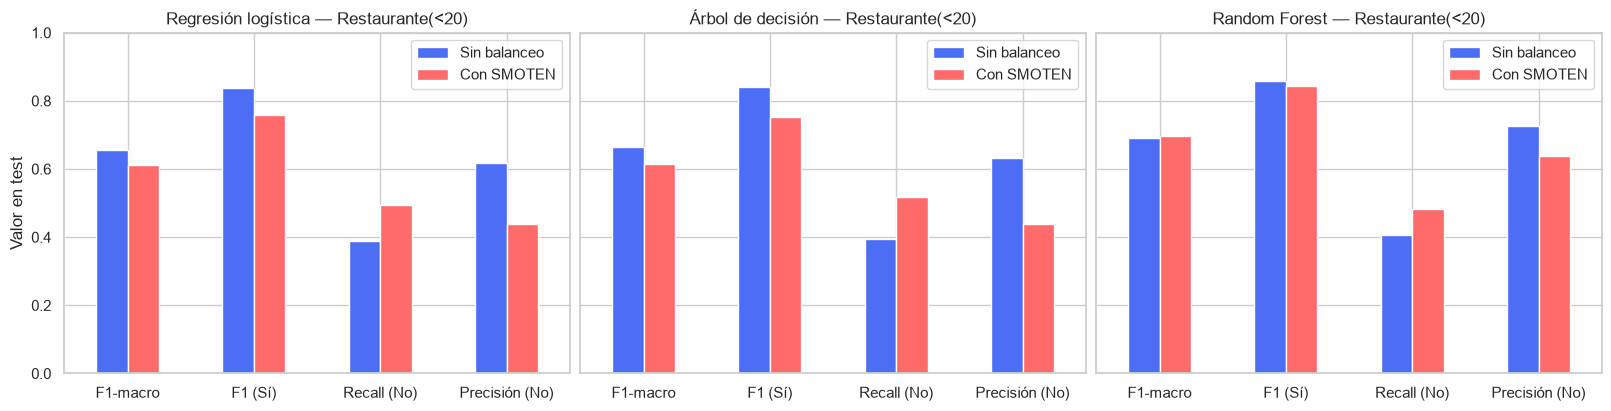

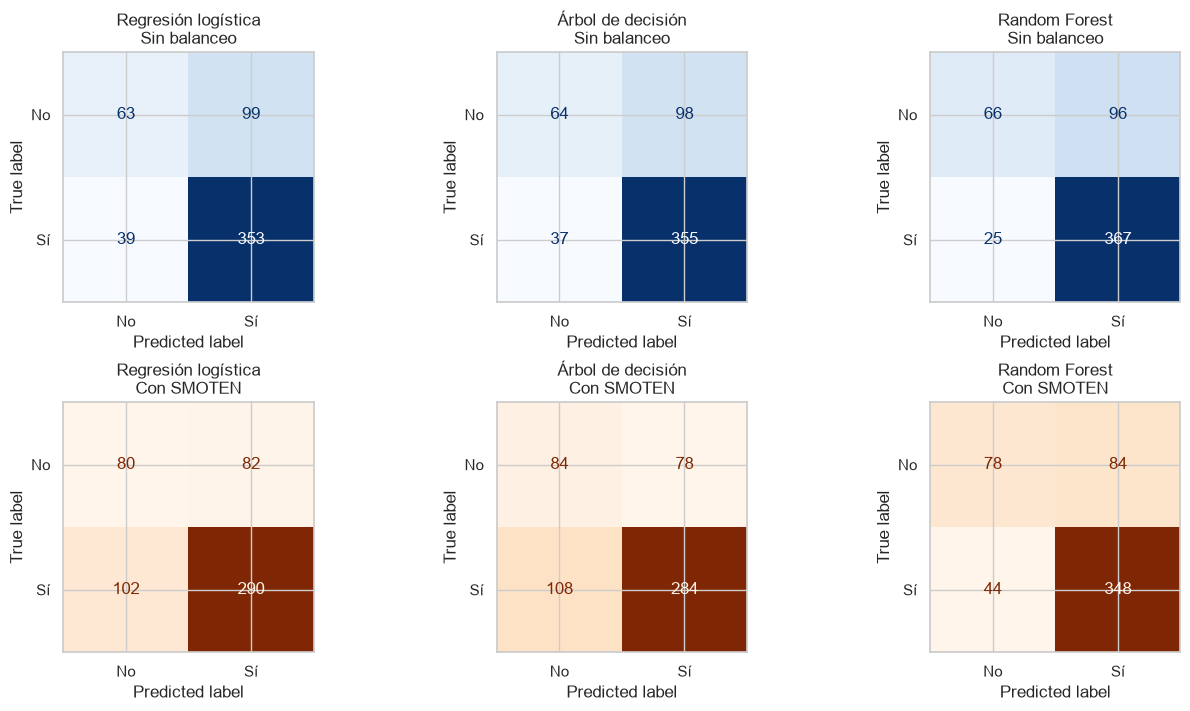

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True, sharey=True)
for ax, nombre in zip(axes, config):
    comp_bal.loc[nombre, ['F1-macro', 'F1 (Sí)', 'Recall (No)', 'Precisión (No)']].T.plot(
        kind='bar', ax=ax, color=['#4C6EF5', '#FF6B6B'])
    ax.set(title=f'{nombre} — {CUPON_DESB}', ylim=(0, 1), ylabel='Valor en test')
    ax.tick_params(axis='x', rotation=0)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
for j, nombre in enumerate(config):
    for i, (etiqueta, g) in enumerate([('Sin balanceo', grids_sin[nombre]), ('Con SMOTEN', grids_bal[nombre])]):
        ConfusionMatrixDisplay.from_predictions(y_test, g.predict(X_test), display_labels=['No', 'Sí'],
                                                cmap='Blues' if i == 0 else 'Oranges', ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f'{nombre}\n{etiqueta}')
plt.show()

**Análisis y recomendación sobre el balanceo.**

- **Regresión logística:** F1-macro 0.657 → 0.612; F1 de Sí 0.836 → 0.759; recall de No 0.389 → 0.494; precisión de No 0.618 → 0.440.
- **Árbol de decisión:** F1-macro 0.663 → 0.614; F1 de Sí 0.840 → 0.753; recall de No 0.395 → 0.519; precisión de No 0.634 → 0.438.
- **Random Forest:** F1-macro 0.690 → 0.697; F1 de Sí 0.859 → 0.845; recall de No 0.407 → 0.481; precisión de No 0.725 → 0.639.

**Recomendación del equipo:** usar **Random Forest + SMOTEN**. Es el candidato con mayor F1-macro en validación cruzada (0.710 vs 0.705 sin balanceo), mejora levemente el F1-macro en test (0.697 vs 0.690) y sube el recall de *No* de 0.41 a 0.48: detecta 12 rechazos más de los 162 del test. A cambio, la precisión de *No* baja de 0.73 a 0.64 y el F1 de *Sí* de 0.859 a 0.845. En regresión logística y en el árbol, SMOTEN no mejora el modelo: su F1-macro en test cae unos 5 puntos. Por eso el balanceo se recomienda solo combinado con Random Forest. Detectar más No ayuda a evitar notificaciones molestas, pero si baja su precisión también se dejan de ofrecer cupones a usuarios que sí aceptarían. Las variaciones de test describen ese compromiso; no justifican cambiar el criterio después de observarlo. Una sola partición no demuestra una mejora estadísticamente significativa.

# 7. Tabla comparativa de modelos (conjunto de test)

Métricas sobre el **conjunto de test** (20% no visto durante la búsqueda de hiperparámetros). Se reportan precisión, recall y F1 de la clase positiva (*Sí, acepta*), el recall de la clase *No* y el F1-macro (métrica de selección).

In [31]:
for nombre in config:
    m = metricas(y_test, grids_bal[nombre].predict(X_test))
    resultados_test[(CUPON_DESB, f'{nombre} + SMOTEN')] = m

tabla_comp = pd.DataFrame(resultados_test).T
tabla_comp.index.names = ['Cupón', 'Modelo']
tabla_comp = tabla_comp[['Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)', 'Recall (No)', 'F1 (No)', 'F1-macro']].sort_index(level=0, sort_remaining=False)

cv_scores = {(c, 'Regresión logística'): grids_rl[c].best_score_ for c in CUPONES}
cv_scores |= {(c, 'Árbol de decisión'): grids_dt[c].best_score_ for c in CUPONES}
cv_scores |= {(c, 'Random Forest'): grids_rf[c].best_score_ for c in CUPONES}
cv_scores |= {(CUPON_DESB, f'{n} + SMOTEN'): grids_bal[n].best_score_ for n in config}
tabla_comp.insert(0, 'F1-macro CV', pd.Series(cv_scores))
tabla_comp.round(4)

F1-macro CV  Precisión (Sí)  \
Cupón            Modelo                                                      
Cafetería        Regresión logística                0.7134          0.6824   
                 Árbol de decisión                  0.7192          0.6743   
                 Random Forest                      0.7646          0.7687   
Restaurante(<20) Regresión logística                0.6540          0.7810   
                 Árbol de decisión                  0.6854          0.7837   
                 Random Forest                      0.7048          0.7927   
                 Regresión logística + SMOTEN       0.6575          0.7796   
                 Árbol de decisión + SMOTEN         0.6426          0.7845   
                 Random Forest + SMOTEN             0.7100          0.8056   

                                               Recall (Sí)  F1 (Sí)  \
Cupón            Modelo                                               
Cafetería        Regresión logística                0.6927   0.6875   
                 Árbol de decisión                  0.7406   0.7059   
                 Random Forest                      0.7783   0.7735   
Restaurante(<20) Regresión logística                0.9005   0.8365   
                 Árbol de decisión                  0.9056   0.8402   
                 Random Forest                      0.9362   0.8585   
                 Regresión logística + SMOTEN       0.7398   0.7592   
                 Árbol de decisión + SMOTEN         0.7245   0.7533   
                 Random Forest + SMOTEN             0.8878   0.8447   

                                               Recall (No)  F1 (No)  F1-macro  
Cupón            Modelo                                                        
Cafetería        Regresión logística                0.6792   0.6843    0.6859  
                 Árbol de decisión                  0.6441   0.6772    0.6915  
                 Random Forest                      0.7669   0.7718    0.7726  
Restaurante(<20) Regresión logística                0.3889   0.4773    0.6569  
                 Árbol de decisión                  0.3951   0.4867    0.6635  
                 Random Forest                      0.4074   0.5217    0.6901  
                 Regresión logística + SMOTEN       0.4938   0.4651    0.6121  
                 Árbol de decisión + SMOTEN         0.5185   0.4746    0.6139  
                 Random Forest + SMOTEN             0.4815   0.5493    0.6970

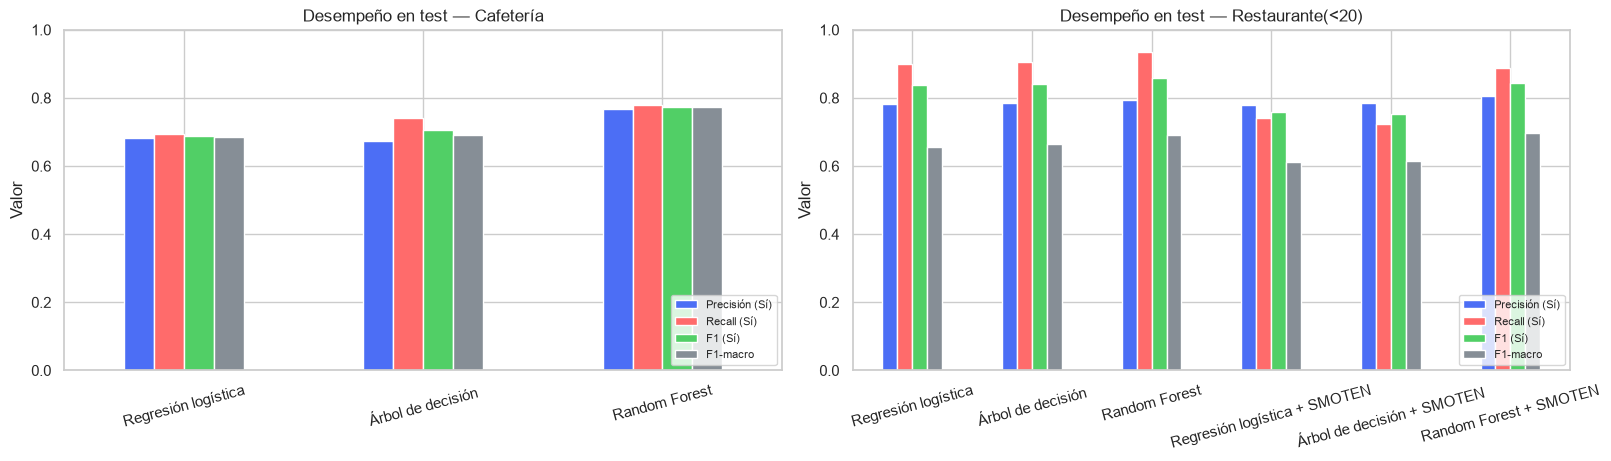

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), constrained_layout=True)
for ax, c in zip(axes, CUPONES):
    tabla_comp.loc[c, ['Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)', 'F1-macro']].plot(kind='bar', ax=ax,
        color=['#4C6EF5', '#FF6B6B', '#51CF66', '#868E96'])
    ax.set(title=f'Desempeño en test — {c}', ylim=(0, 1), ylabel='Valor', xlabel='')
    ax.tick_params(axis='x', rotation=15)
    ax.legend(loc='lower right', fontsize=8)
plt.show()

**Selección del mejor modelo por cupón.**

- **Cafetería: Random Forest**, con F1-macro CV 0.765. En test: precisión de Sí 0.769, recall de Sí 0.778, F1 de Sí 0.774 y F1-macro 0.773.
- **Restaurante(<20): Random Forest + SMOTEN**, con F1-macro CV 0.710. En test: precisión de Sí 0.806, recall de Sí 0.888, F1 de Sí 0.845 y F1-macro 0.697.

El criterio se fijó para dar el mismo peso a aceptar y rechazar: perder una aceptación y molestar a quien rechazaría son costos distintos, pero ambos importan a Ruta Alpes. Sin costos monetarios explícitos, F1-macro es un compromiso razonable. El F1 de Sí se informa por separado porque la competencia de predicciones usa F1 sin precisar su promedio. No se modifica el criterio para mejorar retrospectivamente el test.

# 8. Variables más relevantes

Se complementa la importancia por reducción de impureza de P8/P10 con la **permutación del Random Forest en test**: una caída grande de F1-macro indica que el modelo depende de esa variable original. No implica causalidad; variables correlacionadas pueden repartirse la importancia y las barras de desviación no son intervalos de confianza.

Los **coeficientes logísticos** describen cambios en log-odds, manteniendo el resto fijo. En ordinales corresponden a una desviación estándar; en indicadores One-Hot, a un cambio 0→1. Por ello no todas sus magnitudes son directamente comparables. Con todas las categorías de una variable nominal, se interpretan contrastes entre coeficientes, no cada signo contra una categoría de referencia inexistente.

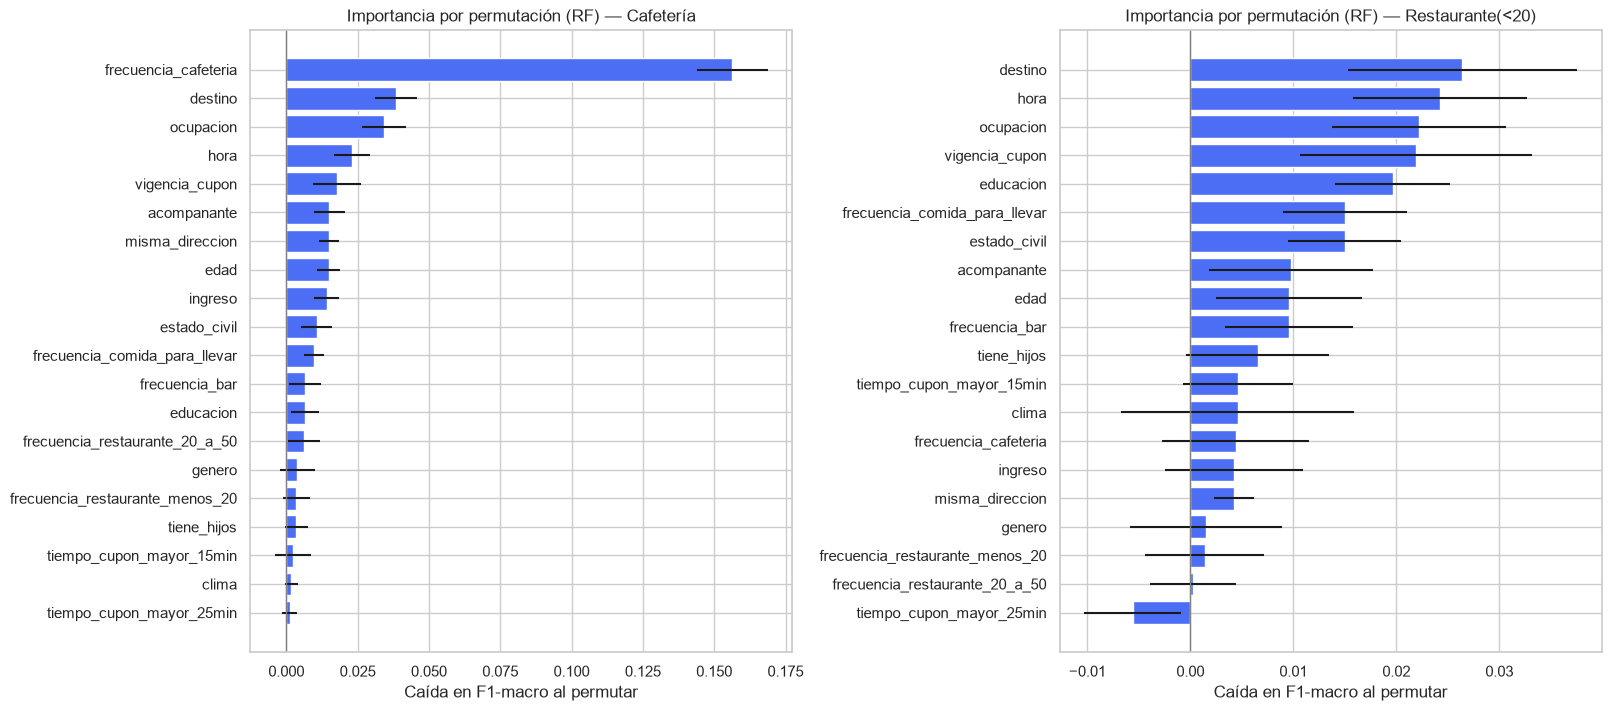

,Cafetería,Restaurante(<20),Imp. Cafetería,Imp. Restaurante(<20)
frecuencia_cafeteria,1,14,0.1564,0.0044
destino,2,1,0.0385,0.0264
ocupacion,3,3,0.0342,0.0222
hora,4,2,0.0229,0.0242
vigencia_cupon,5,4,0.0176,0.0219
acompanante,6,8,0.0150,0.0098
misma_direccion,7,16,0.0149,0.0042
edad,8,9,0.0148,0.0096
ingreso,9,15,0.0141,0.0042
estado_civil,10,7,0.0106,0.0150


In [33]:
importancias = {}
for c in CUPONES:
    X_train, X_test, y_train, y_test = splits[c]
    with parallel_config(max_nbytes=None):
        r = permutation_importance(grids_rf[c].best_estimator_, X_test, y_test, scoring='f1_macro',
                               n_repeats=15, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    importancias[c] = pd.DataFrame({'media': r.importances_mean, 'std': r.importances_std}, index=X_test.columns)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)
for ax, c in zip(axes, CUPONES):
    imp = importancias[c].sort_values('media')
    ax.barh(imp.index, imp['media'], xerr=imp['std'], color='#4C6EF5')
    ax.axvline(0, color='gray', lw=1)
    ax.set(title=f'Importancia por permutación (RF) — {c}', xlabel='Caída en F1-macro al permutar')
plt.show()

pd.concat({c: importancias[c]['media'].rank(ascending=False).astype(int) for c in CUPONES}, axis=1) \
  .assign(**{f'Imp. {c}': importancias[c]['media'].round(4) for c in CUPONES}) \
  .sort_values('Cafetería')

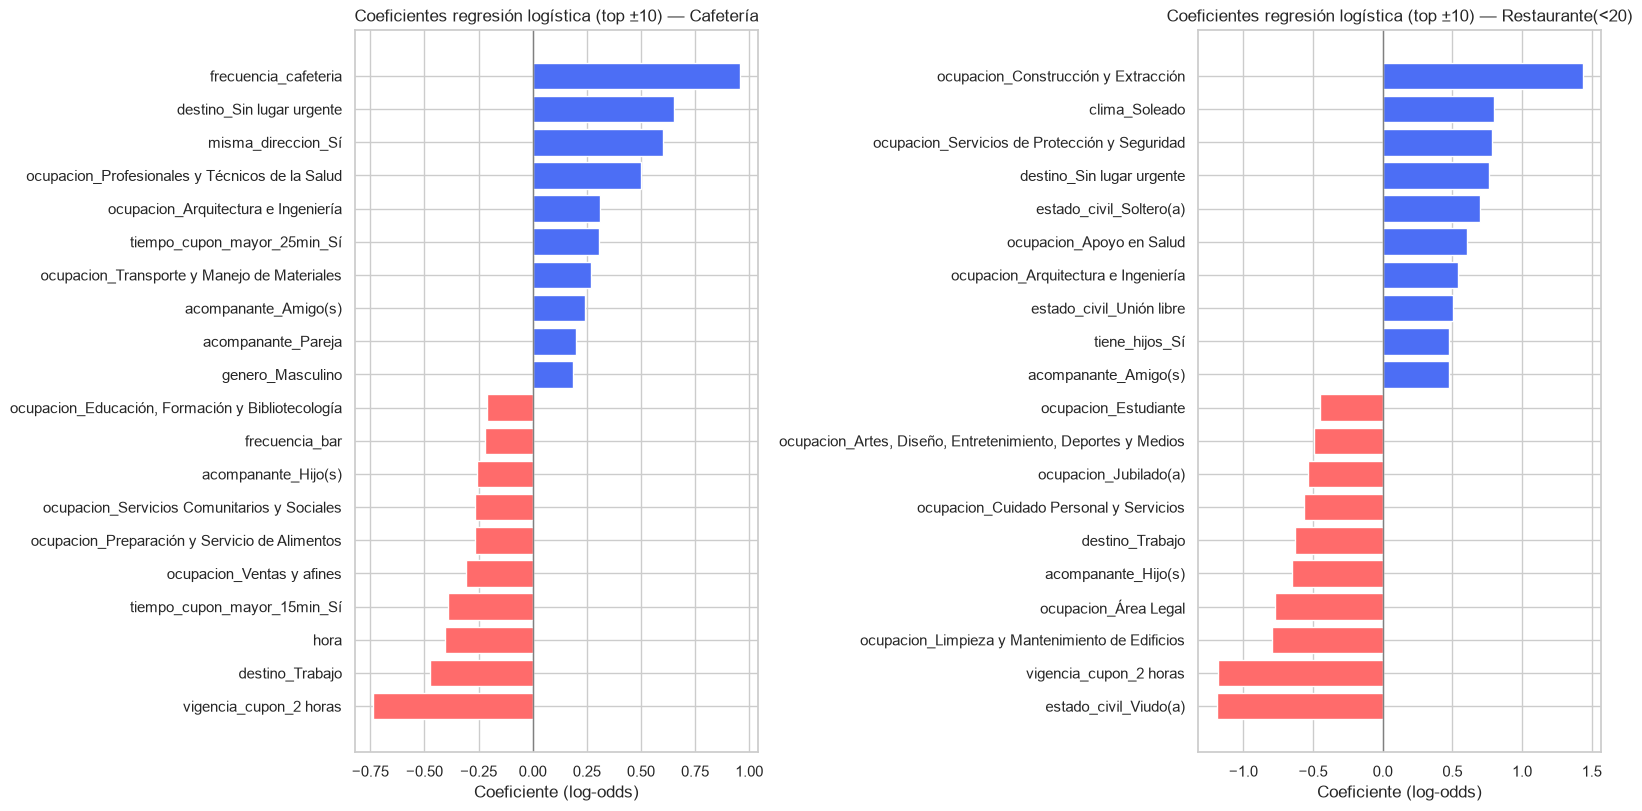

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 8), constrained_layout=True)
coefs_rl = {}
for ax, c in zip(axes, CUPONES):
    best = grids_rl[c].best_estimator_
    nombres = best.named_steps['preprocesador'].get_feature_names_out()
    nombres = [n.split('__', 1)[1] for n in nombres]
    coef = pd.Series(best.named_steps['modelo'].coef_[0], index=nombres)
    coefs_rl[c] = coef
    top = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values()
    ax.barh(top.index, top.values, color=np.where(top.values > 0, '#4C6EF5', '#FF6B6B'))
    ax.axvline(0, color='gray', lw=1)
    ax.set(title=f'Coeficientes regresión logística (top ±10) — {c}', xlabel='Coeficiente (log-odds)')
plt.show()

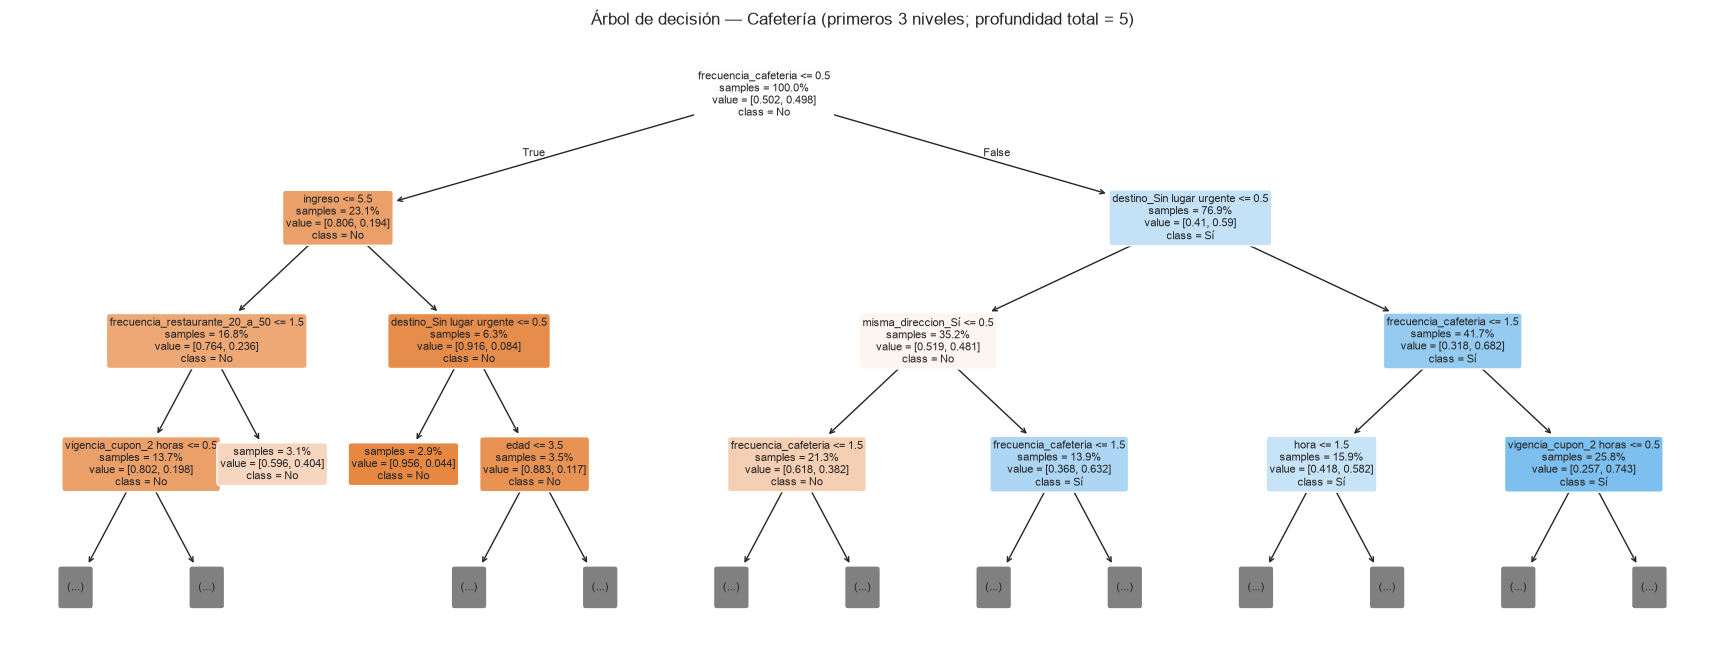

|--- frecuencia_cafeteria <= 0.50
|   |--- ingreso <= 5.50
|   |   |--- frecuencia_restaurante_20_a_50 <= 1.50
|   |   |   |--- vigencia_cupon_2 horas <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- vigencia_cupon_2 horas >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- frecuencia_restaurante_20_a_50 >  1.50
|   |   |   |--- weights: [59.00, 40.00] class: 0
|   |--- ingreso >  5.50
|   |   |--- destino_Sin lugar urgente <= 0.50
|   |   |   |--- weights: [87.00, 4.00] class: 0
|   |   |--- destino_Sin lugar urgente >  0.50
|   |   |   |--- edad <= 3.50
|   |   |   |   |--- weights: [47.00, 3.00] class: 0
|   |   |   |--- edad >  3.50
|   |   |   |   |--- weights: [51.00, 10.00] class: 0
|--- frecuencia_cafeteria >  0.50
|   |--- destino_Sin lugar urgente <= 0.50
|   |   |--- misma_direccion_Sí <= 0.50
|   |   |   |--- frecuencia_cafeteria <= 1.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- frecuencia_cafeteria >  1.50


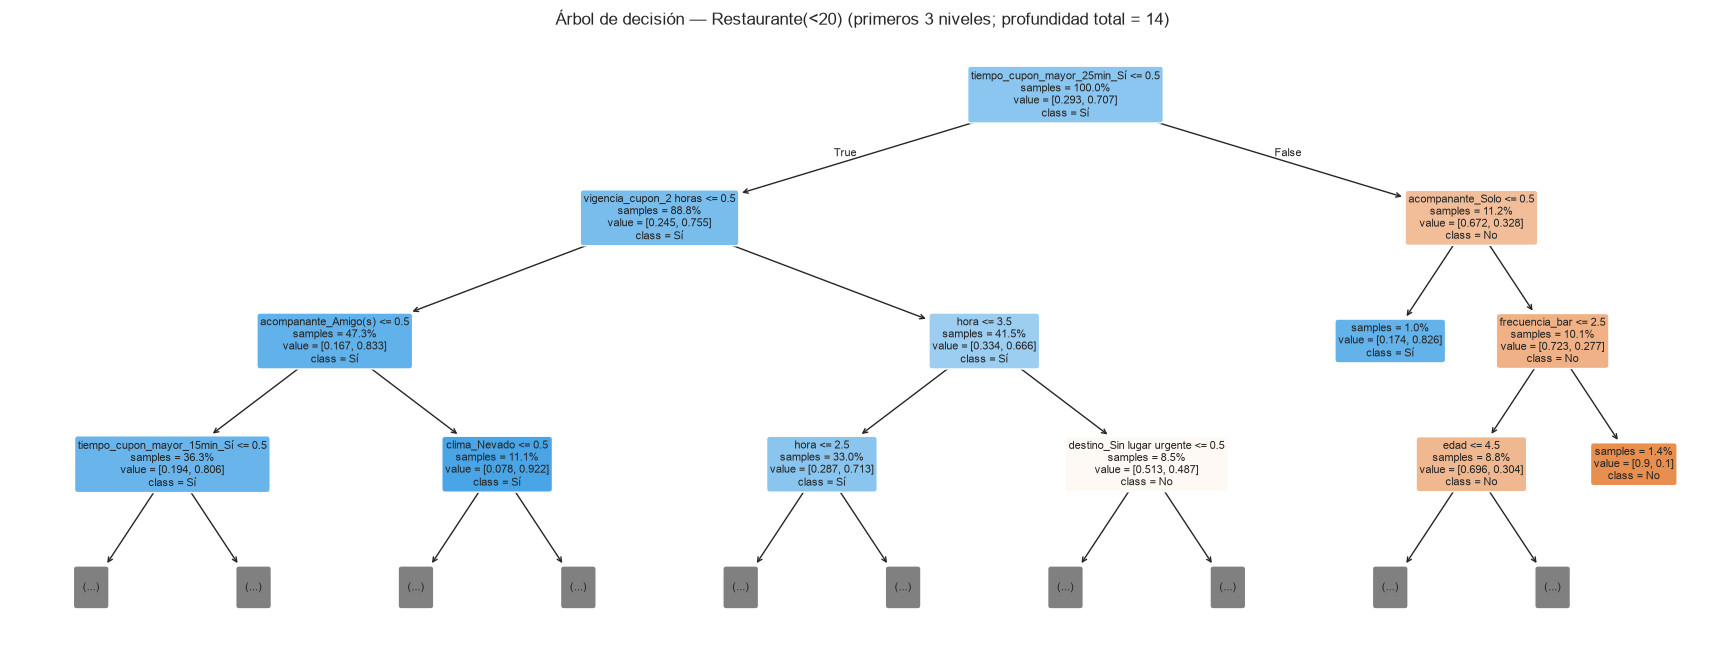

|--- tiempo_cupon_mayor_25min_Sí <= 0.50
|   |--- vigencia_cupon_2 horas <= 0.50
|   |   |--- acompanante_Amigo(s) <= 0.50
|   |   |   |--- tiempo_cupon_mayor_15min_Sí <= 0.50
|   |   |   |   |--- truncated branch of depth 11
|   |   |   |--- tiempo_cupon_mayor_15min_Sí >  0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |--- acompanante_Amigo(s) >  0.50
|   |   |   |--- clima_Nevado <= 0.50
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- clima_Nevado >  0.50
|   |   |   |   |--- truncated branch of depth 3
|   |--- vigencia_cupon_2 horas >  0.50
|   |   |--- hora <= 3.50
|   |   |   |--- hora <= 2.50
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- hora >  2.50
|   |   |   |   |--- truncated branch of depth 8
|   |   |--- hora >  3.50
|   |   |   |--- destino_Sin lugar urgente <= 0.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- destino_Sin lugar urgente >  0.50
|   |   |   |   |--- truncated branch of depth 3
|--- t

In [35]:
# Reglas del árbol de decisión (primeros 3 niveles) para cada cupón
for c in CUPONES:
    best = grids_dt[c].best_estimator_
    nombres = [n.split('__', 1)[1] for n in best.named_steps['preprocesador'].get_feature_names_out()]
    fig, ax = plt.subplots(figsize=(22, 8))
    plot_tree(best.named_steps['modelo'], max_depth=3, feature_names=nombres, class_names=['No', 'Sí'],
              filled=True, rounded=True, fontsize=8, proportion=True, impurity=False, ax=ax)
    ax.set_title(f'Árbol de decisión — {c} (primeros 3 niveles; profundidad total = {best.named_steps["modelo"].get_depth()})')
    plt.show()
    print(export_text(best.named_steps['modelo'], feature_names=nombres, max_depth=3, show_weights=True))

**Variables más relevantes.**

- **Cafetería:** las mayores caídas de F1-macro al permutar corresponden a `frecuencia_cafeteria` (0.156), `destino` (0.039), `ocupacion` (0.034), `hora` (0.023).
- **Restaurante(<20):** las mayores caídas de F1-macro al permutar corresponden a `destino` (0.026), `hora` (0.024), `ocupacion` (0.022), `vigencia_cupon` (0.022).

Se interpretan los bosques **sin balanceo** para comparar ambos cupones bajo el mismo esquema, no el reajuste final de producción. Las variables con caída cercana a cero aportan poco a ese bosque en este test; no necesariamente son inútiles en otra muestra. En Cafetería, el coeficiente de frecuencia de visita es positivo (0.956 por desviación estándar), coherente con la asociación exploratoria. Los indicadores nominales deben leerse mediante contrastes entre categorías. La importancia mide dependencia predictiva, no causalidad.


# 9. Predicciones sobre los datos sin etiqueta

Se selecciona el mayor **F1-macro promedio de validación cruzada** entre los candidatos de cada cupón. Test describe la generalización, pero no determina nuevos hiperparámetros ni la selección. Después de evaluar, se clona el pipeline elegido y se reajusta con todos los datos etiquetados del cupón. Estas métricas de test pertenecen al ajuste anterior (80%), no a este ajuste final.

Se preservan las 20 filas, su orden y todas las columnas originales de `Lab3_datos_Prueba.xlsx`; únicamente se añade `acepta_cupon`. Este archivo no tiene etiquetas para calcular su F1.


In [36]:

candidatos = {c: {'Regresión logística': grids_rl[c], 'Árbol de decisión': grids_dt[c], 'Random Forest': grids_rf[c]} for c in CUPONES}
candidatos[CUPON_DESB].update({f'{nombre} + SMOTEN': g for nombre, g in grids_bal.items()})
seleccion = {c: max(candidatos[c], key=lambda nombre: candidatos[c][nombre].best_score_) for c in CUPONES}
display(pd.DataFrame([{'Cupón': c, 'Modelo elegido por CV': nombre, 'F1-macro CV': candidatos[c][nombre].best_score_} for c, nombre in seleccion.items()]))

prueba_original = pd.read_excel('Data/Lab3_datos_Prueba.xlsx')
assert prueba_original['cupon'].isin(CUPONES).all()
predicciones = prueba_original.copy()
predicciones['acepta_cupon'] = pd.Series(index=predicciones.index, dtype='object')
modelos_finales = {}
for c in CUPONES:
    X_todo, y_todo = preparar(subconjuntos[c])
    final = clone(candidatos[c][seleccion[c]].best_estimator_)
    final.fit(X_todo, y_todo)
    modelos_finales[c] = final
    mascara = prueba_original['cupon'].eq(c)
    X_nuevo = prueba_original.loc[mascara, X_todo.columns]
    predicciones.loc[mascara, 'acepta_cupon'] = np.where(final.predict(X_nuevo) == 1, 'Sí', 'No')

pd.testing.assert_frame_equal(predicciones[prueba_original.columns], prueba_original)
assert predicciones['acepta_cupon'].isin(['Sí', 'No']).all()
predicciones.to_csv('Lab3_datos_Prueba.csv', index=False, encoding='utf-8-sig')
print(f'CSV exportado: {len(predicciones)} filas y {len(predicciones.columns)} columnas.')
display(predicciones[['cupon', 'acepta_cupon']])


,Cupón,Modelo elegido por CV,F1-macro CV
0,Cafetería,Random Forest,0.764608
1,Restaurante(<20),Random Forest + SMOTEN,0.709967


CSV exportado: 20 filas y 26 columnas.


,cupon,acepta_cupon
0,Cafetería,Sí
1,Cafetería,Sí
2,Cafetería,Sí
3,Cafetería,Sí
4,Restaurante(<20),Sí
5,Restaurante(<20),Sí
6,Restaurante(<20),No
7,Restaurante(<20),Sí
8,Restaurante(<20),Sí
9,Cafetería,No


# 10. Análisis de resultados

### 1. ¿Qué características se relacionan con la aceptación?

En **Cafetería** destacan `frecuencia_cafeteria`, `destino`, `ocupacion`; en **Restaurante(<20)**, `destino`, `hora`, `ocupacion`, según la permutación del bosque. En la exploración, Cafetería tiene 18.8% de aceptación entre quienes nunca van (925 registros), frente a 64.6% entre quienes van 1 a 3 veces (1038). En Restaurante, la aceptación es 83.2% con vigencia de un día (1349 registros), frente a 58.9% con dos horas (1427); también cae de 75.5% a 32.6% cuando el trayecto al cupón supera 25 minutos. Son tasas descriptivas sin ajuste por otras variables, no efectos causales del perfil o contexto.

### 2. ¿Hay variables redundantes o poco informativas?

`direccion_opuesta` es el complemento de `misma_direccion` (V de Cramér = 1); `tiempo_cupon_mayor_5min` y el tipo de cupón son constantes dentro de cada problema. `vehiculo` tiene cerca de 99% de nulos. Por eso se retiraron. Temperatura y clima son parcialmente redundantes: quitar temperatura simplifica, pero pierde detalle en días soleados. Entre las retenidas, las menores importancias por permutación son `tiempo_cupon_mayor_25min` y `clima` en Cafetería, y `tiempo_cupon_mayor_25min` y `frecuencia_restaurante_20_a_50` en Restaurante; no se eliminan retrospectivamente usando test.

### 3. ¿Difieren los modelos entre los dos cupones?

Los modelos elegidos alcanzan F1-macro de test **0.773** en Cafetería y **0.697** en Restaurante. Sus recalls de No son **0.767** y **0.481**. Restaurante tiene menos registros y una base de aceptación de aproximadamente 71%, frente a 50% en Cafetería: predecir Sí es más fácil allí, pero distinguir rechazos sigue siendo difícil. También cambia el peso de hábitos y contexto; por eso el F1 positivo de ambos problemas no debe compararse aisladamente.

### 4. ¿Mejoró el balanceo de Restaurante?

La sección 6 contrasta los tres pares sobre el mismo test y muestra F1-macro, F1 positivo y recall/precisión de No. La recomendación final es **Random Forest + SMOTEN** por su validación cruzada. El balanceo no debe considerarse beneficioso solo porque aumenta el recall minoritario: hay que revisar cuánto F1 y precisión se pierde o gana, y cuántos cupones aceptables se omitirían. La tabla permite distinguir ese intercambio por algoritmo.

### 5. ¿Cómo interpretar un árbol o un bosque?

Los árboles de la sección 8 permiten leer reglas completas. En **Cafetería**, nunca visitar cafeterías, tener ingreso anual de al menos $75.000 e ir a casa o trabajo conduce a una hoja de rechazo (87 No y 4 Sí en train). En **Restaurante**, estar a más de 25 minutos e ir acompañado (no solo) conduce a una hoja de aceptación (19 Sí y 4 No); yendo solo y con frecuencia de bar de al menos 4 a 8 visitas, una hoja predice rechazo (27 No y 3 Sí).

Estas reglas muestran interacciones útiles para explicar decisiones, no recomendaciones de excluir perfiles. Las hojas pequeñas tienen incertidumbre y sus proporciones son de entrenamiento. Los bosques sin balanceo dependen especialmente de `frecuencia_cafeteria` y `destino` en Cafetería, y `destino` y `hora` en Restaurante. Sus importancias no dan dirección causal y las reglas del árbol individual no describen exactamente el bosque. Las ramas truncadas del gráfico requieren seguir más condiciones.

### 6. ¿Cómo integrarlo a la aplicación en tiempo real?

La aplicación reuniría el contexto disponible y los hábitos autorizados, aplicaría el pipeline del tipo de cupón y obtendría `predict_proba`. Antes de comparar probabilidades entre modelos habría que comprobar su calibración. Se enviaría una oferta elegible solo si supera un umbral definido con validación y costos de negocio, con límite de frecuencia y evitando interacciones que distraigan al conducir. Se registrarían oferta, aceptación y rechazo para monitorear precisión, recall de No, cambios de distribución y diferencias entre grupos. Un piloto A/B mediría aceptación y molestias frente a la estrategia actual.

### 7. ¿Qué limita la personalización demográfica?

Un promedio de grupo no describe a cada persona: alguien puede recibir menos oportunidades por su edad o ingreso aunque sus preferencias sean distintas. Además, las categorías son gruesas, los hábitos cambian y faltan variables del contexto. La encuesta no equivale a una prueba de uso real, y sin identificador no se garantiza independencia por conductor. Conviene permitir desactivar la personalización, minimizar datos y comparar una alternativa basada solo en contexto/hábitos. No se ha medido aquí la equidad por subgrupos ni puede afirmarse que el sistema sea justo.

### 8. ¿Qué sesgos e implicaciones éticas existen?

**Representación:** ocupaciones y estados civiles poco frecuentes tienen menos evidencia; los errores pueden concentrarse allí. **Medición y transferencia:** respuestas de encuesta y rangos de edad/ingreso pueden no representar preferencias reales ni a los usuarios locales. **Retroalimentación:** si solo se ofrecen cupones a perfiles favorecidos, solo se observan sus respuestas y se refuerza la selección. Ocupación y educación también pueden funcionar como proxies de ingreso, incluso si se retira esa columna.

Para evaluar estos riesgos se deberían reportar tasas de exposición y métricas por edad, género e ingreso, con tamaños de muestra e incertidumbre, y mantener exploración controlada para no excluir grupos. En precios dinámicos, inferir disposición de pago podría traducirse en cobros distintos y perjuicios económicos sistemáticos. Un modelo útil para cupones no justifica automáticamente ese uso: requeriría otra evaluación de finalidad, equidad, consentimiento y mecanismos de reclamo.


# 11. Uso de herramientas de IA generativa

### Declaración de uso

| Herramienta | Tipo de uso |
|---|---|
| **Claude Code** (modelo Claude Opus 5.5, Anthropic) | Generación inicial del código repetitivo a partir de las prácticas P1, P2, P7, P8, P9 y P10 (exploración, pipelines, grids, gráficas y tablas), consulta del cambio de API de scikit-learn 1.9 (`penalty` → `l1_ratio`), presentación de opciones para cada decisión, revisión del avance y apoyo en redacción. |
| **ChatGPT 6 Astra** (OpenAI) | Implementación de los cambios que indicó el equipo (por ejemplo, SMOTEN), una caché de transformaciones con `joblib.Memory` para reducir el tiempo de ejecución de los grids, implementación de la selección por validación cruzada y del reajuste final, depuración, primera redacción del análisis y exportación de HTML/CSV. |

**Todas las decisiones de criterio las tomó el equipo.** Las herramientas se usaron para lo repetitivo: trasladar al caso Ruta Alpes el código de las prácticas del curso, implementar el pipeline y la caché, y ejecutar y depurar. Cuando había una decisión metodológica, la IA presentaba alternativas con sus ventajas y desventajas, y el equipo elegía:

| Decisión | Alternativas consideradas | Elección del equipo |
|---|---|---|
| Nulos en `frecuencia_*` | Imputar moda en pipeline / eliminar filas / categoría "Sin información" | Imputar moda dentro del pipeline |
| Columnas a eliminar | `vehiculo`, `tiempo_cupon_mayor_5min`, `direccion_opuesta`, `temperatura` | Las cuatro (más `cupon`) |
| Duplicados | Eliminar / mantener | Eliminar |
| Codificación | Ordinal + One-Hot / One-Hot para todo | Ordinal con el orden del diccionario + One-Hot |
| Métrica de búsqueda | F1 de la clase "Sí" / F1-macro | F1-macro |
| Partición y CV | 80/20 + 5 folds / 80/20 + 10 folds / 75/25 + 5 folds | 80/20 estratificado, 5 folds |
| Rangos de hiperparámetros | Grid amplio / grid reducido de las prácticas | Grid amplio |
| Técnica de balanceo | SMOTE / SMOTENC / SMOTEN | SMOTENC en el primer avance; **Daniel Vergara decidió cambiarlo a SMOTEN** y se lo indicó a ChatGPT 6 Astra para implementarlo |
| Alcance del balanceo | Los 3 algoritmos / solo el mejor | Los 3 algoritmos |
| Selección del modelo final | Por test / por F1-macro de CV | Por F1-macro de CV, con reajuste final sobre todos los datos etiquetados |

### Prompts principales

**Claude Code:**
1. *"Tengo que hacer el siguiente laboratorio, las instrucciones completas están en el .md, la rúbrica está en el .pdf y tenemos la data en la carpeta Data. Quiero que revises todo y empecemos a trabajar. Fíjate que el .md especifica que si voy a usar inteligencia artificial no solo la debo declarar sino también debo yo tomar las decisiones importantes, así que tú vas a hacer todo lo repetitivo y en el momento que haya que tomar una decisión es cuando vas a pedir mi input. Guíate del repo de la clase: https://github.com/ISIS-2611-AprendizajeMaquina/MaterialDeClase-ISIS-2611.git"*
2. *"Hicieron unos cambios, revisa y me dices qué opinas (antes de cambiar cosas)."*
3. *(Resumen)* Corregir la documentación de la decisión de SMOTEN, aclarar que todas las decisiones las tomó el equipo, restaurar la exploración detallada, alinear las versiones de las librerías para que los resultados sean reproducibles y regenerar el HTML.

**ChatGPT 6 Astra (resumen):**
1. *"Leer muy bien Laboratorio 3_Clasificación.md y la rúbrica del PDF; continuar Lab3_Clasificacion.ipynb respetando los avances del compañero; basarse obligatoriamente en las prácticas del repositorio ISIS-2611; adaptar el código para cumplir la rúbrica, redactar explicaciones buenas pero breves y correr el notebook con los datos de /Data."*
2. Reemplazar SMOTENC por SMOTEN en la sección de balanceo (decisión de Daniel).
3. Reducir el tiempo de ejecución de las búsquedas de hiperparámetros (resultó en la caché de transformaciones).

### Análisis crítico del resultado

- **Correcto y útil:** la adaptación de los pipelines (`ColumnTransformer`, `Pipeline` de `imblearn`), la validación cruzada estratificada y las métricas por clase de las prácticas. La caché no introduce fuga de datos: guarda cada transformación según sus datos de entrada y parámetros, así que no comparte ajustes entre folds distintos.
- **Errores e imprecisiones identificados:**
  - Claude escribió hallazgos exploratorios antes de verificarlos (por ejemplo, que la misma dirección aumentaba la aceptación en Restaurante, cuando en realidad baja de 72% a 64%) y citó una asociación `ocupacion`–`edad` que no está entre las más altas de la V de Cramér. Se corrigieron contrastando con las tasas y la tabla calculadas.
  - ChatGPT 6 Astra documentó el cambio a SMOTEN como una adaptación propia de la IA, cuando fue una decisión de Daniel. También reemplazó la lectura exploratoria por un texto genérico y dejó frases de relleno en esta sección. Se corrigieron.
  - El parámetro `penalty` de P7 está obsoleto en scikit-learn 1.9; la regularización se expresa con `l1_ratio`.
  - Al re-ejecutar en otro equipo (Windows vs macOS) cambiaban algunos hiperparámetros en empates prácticos del grid (diferencias de milésimas en CV), incluso con las mismas versiones de `requirements.txt`. Las predicciones finales no cambiaron, y los números citados en el texto corresponden a la ejecución que se entrega.
- **Conceptos del curso que permitieron evaluar las respuestas:** fuga de información (imputar y balancear dentro del pipeline), diferencia entre F1 de la clase positiva y F1-macro, recall de la clase minoritaria, sobreajuste (F1 de train ≈ 0.999 frente a CV en Random Forest) e interpretación no causal de importancias y coeficientes.

### Aportes propios del equipo

- **Desarrollado o decidido por el equipo:** todas las decisiones de la tabla anterior, incluido el cambio a SMOTEN (Daniel Vergara), el criterio de selección del modelo y la recomendación sobre el balanceo. El equipo revisó las salidas, los números citados en el texto y las conclusiones del análisis.
- **Ajustes sobre lo generado:** se corrigieron afirmaciones exploratorias sin respaldo y la atribución errónea de decisiones a la IA, se eliminó una celda auxiliar que no hacía parte del entregable y se fijaron versiones de librerías para que el notebook sea reproducible.
- **Aprendizajes:** en Restaurante(<20) la clase minoritaria es *No* y no *Sí*, lo que cambia qué recall importa. Balancear aumenta el recall de la minoritaria, pero a costa de su precisión, y no siempre mejora el F1-macro. La elección entre SMOTENC y SMOTEN es un compromiso entre usar el orden de las ordinales y generar categorías válidas. Por último, el texto generado por IA debe verificarse contra los datos, porque puede afirmar cosas plausibles pero falsas.

# 12. Video explicativo

El archivo `guion_video.md` propone una exposición de menos de tres minutos para el equipo técnico de Ruta Alpes: preparación, comparación, interpretación y recomendación. **La grabación del video queda a cargo de Julian Pinto y Daniel Vergara**; el guion no reemplaza ese entregable.
